### Building and Learning a Bayesian Network

Note that from our course we are subscribing to these notions:

**AI science:** define a probabilistic model, reason about its assumptions, and perform correct inference.

**AI engineering:** use a modern LLM to help translate a specification into executable code, then validate, test, and revise that code.

We will keep one Bayesian network throughout:

$$
C \rightarrow R,\qquad
C \rightarrow S,\qquad
R,S \rightarrow W,
$$

where

- $C$: Cloudy
- $R$: Rain
- $S$: Sprinkler
- $W$: WetGrass

The main engineering pipeline is

$$
\boxed{\text{natural-language specification}}
\rightarrow
\boxed{\text{LLM-generated code}}
\rightarrow
\boxed{\text{validation}}
\rightarrow
\boxed{\text{execution}}
\rightarrow
\boxed{\text{tests}}.
$$

The LLM will **not** replace Bayesian-network inference or parameter estimation. It will help generate the program that calls a probabilistic modelling library.

#### Setup

The notebook uses:

- `pgmpy` for Bayesian networks;
- `pandas` and `numpy` for data;
- `matplotlib` for plots;
- Hugging Face `transformers` for a local open-source coding LLM.

For the LLM we use:

```text
Qwen/Qwen2.5-Coder-7B-Instruct (15GB; not using this)
```

It is an instruction-tuned code model that can be loaded locally with Hugging Face Transformers.

Run the installation cell once if the packages are not already installed.

In [1]:
# Uncomment this line if these packages are not already installed.
# %pip install -q "pgmpy>=1.0" "transformers>=4.45" accelerate pandas matplotlib

In [2]:
import ast
import itertools
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

np.random.seed(7)

C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
# Record library versions: generated code must be tested against the *installed* API.
import sys, platform, warnings, pgmpy, transformers, torch

# pgmpy 1.1 warns that the legacy estimator classes will move; keep the output readable.
warnings.filterwarnings("ignore", category=FutureWarning)
print("Python      :", sys.version.split()[0], platform.system())
print("pgmpy       :", pgmpy.__version__)
print("transformers:", transformers.__version__)
print("torch       :", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Python      : 3.13.14 Windows
pgmpy       : 1.1.2
transformers: 5.17.0
torch       : 2.14.0+cpu | CUDA available: False


#### Let's start with this:
Before involving an LLM, we need a trusted mathematical specification.

The graph is

$$
C \rightarrow R,\qquad
C \rightarrow S,\qquad
R \rightarrow W,\qquad
S \rightarrow W.
$$

The joint distribution factorises as

$$
P(C,R,S,W)
=
P(C)P(R\mid C)P(S\mid C)P(W\mid R,S).
$$

We use binary states:

$$
0=\text{False},\qquad 1=\text{True}.
$$

#### The probabilities

We will use the following parameters:

$$
P(C=1)=0.5.
$$

For Rain:

$$
P(R=1\mid C=0)=0.2,
\qquad
P(R=1\mid C=1)=0.8.
$$

For Sprinkler:

$$
P(S=1\mid C=0)=0.5,
\qquad
P(S=1\mid C=1)=0.1.
$$

For WetGrass:

$$
\begin{aligned}
P(W=1\mid R=0,S=0)&=0.01,\\
P(W=1\mid R=0,S=1)&=0.90,\\
P(W=1\mid R=1,S=0)&=0.90,\\
P(W=1\mid R=1,S=1)&=0.99.
\end{aligned}
$$

These numbers define the probabilistic model. The software must encode them without changing their meaning.

#### We trust ourself first (?). So, we implement a version ourself.

We first implement the network ourselves.

This is important because later the LLM-generated implementation needs something trustworthy to compare against.

For a binary variable, each `TabularCPD` has one row for state 0 and one row for state 1.

In [4]:
def build_reference_model():
    """Construct the trusted Sprinkler Bayesian network."""

    model = DiscreteBayesianNetwork([
        ("Cloudy", "Rain"),
        ("Cloudy", "Sprinkler"),
        ("Rain", "WetGrass"),
        ("Sprinkler", "WetGrass"),
    ])

    # P(Cloudy)
    cpd_cloudy = TabularCPD(
        variable="Cloudy",
        variable_card=2,
        values=[
            [0.5],  # P(Cloudy=0)
            [0.5],  # P(Cloudy=1)
        ],
    )

    # P(Rain | Cloudy)
    # Columns correspond to Cloudy=0, Cloudy=1.
    cpd_rain = TabularCPD(
        variable="Rain",
        variable_card=2,
        values=[
            [0.8, 0.2],  # P(Rain=0 | Cloudy)
            [0.2, 0.8],  # P(Rain=1 | Cloudy)
        ],
        evidence=["Cloudy"],
        evidence_card=[2],
    )

    # P(Sprinkler | Cloudy)
    # Columns correspond to Cloudy=0, Cloudy=1.
    cpd_sprinkler = TabularCPD(
        variable="Sprinkler",
        variable_card=2,
        values=[
            [0.5, 0.9],  # P(Sprinkler=0 | Cloudy)
            [0.5, 0.1],  # P(Sprinkler=1 | Cloudy)
        ],
        evidence=["Cloudy"],
        evidence_card=[2],
    )

    # P(WetGrass | Rain, Sprinkler)
    # With evidence=["Rain", "Sprinkler"], columns are ordered as:
    # (Rain=0, Sprinkler=0),
    # (Rain=0, Sprinkler=1),
    # (Rain=1, Sprinkler=0),
    # (Rain=1, Sprinkler=1).
    cpd_wetgrass = TabularCPD(
        variable="WetGrass",
        variable_card=2,
        values=[
            [0.99, 0.10, 0.10, 0.01],  # WetGrass=0
            [0.01, 0.90, 0.90, 0.99],  # WetGrass=1
        ],
        evidence=["Rain", "Sprinkler"],
        evidence_card=[2, 2],
    )

    model.add_cpds(
        cpd_cloudy,
        cpd_rain,
        cpd_sprinkler,
        cpd_wetgrass,
    )

    return model

reference_model = build_reference_model()
print("Model valid:", reference_model.check_model())
print("Edges:", list(reference_model.edges()))

Model valid: True
Edges: [('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')]


#### Let's the CPDs

Do not treat the CPT representation as a formatting detail.

If the parent ordering or column ordering is wrong, the program can represent a different probability distribution even though the numerical values look familiar.

In [5]:
for cpd in reference_model.get_cpds():
    print(cpd)
    print()

+-----------+-----+
| Cloudy(0) | 0.5 |
+-----------+-----+
| Cloudy(1) | 0.5 |
+-----------+-----+

+---------+-----------+-----------+
| Cloudy  | Cloudy(0) | Cloudy(1) |
+---------+-----------+-----------+
| Rain(0) | 0.8       | 0.2       |
+---------+-----------+-----------+
| Rain(1) | 0.2       | 0.8       |
+---------+-----------+-----------+

+--------------+-----------+-----------+
| Cloudy       | Cloudy(0) | Cloudy(1) |
+--------------+-----------+-----------+
| Sprinkler(0) | 0.5       | 0.9       |
+--------------+-----------+-----------+
| Sprinkler(1) | 0.5       | 0.1       |
+--------------+-----------+-----------+

+-------------+--------------+--------------+--------------+--------------+
| Rain        | Rain(0)      | Rain(0)      | Rain(1)      | Rain(1)      |
+-------------+--------------+--------------+--------------+--------------+
| Sprinkler   | Sprinkler(0) | Sprinkler(1) | Sprinkler(0) | Sprinkler(1) |
+-------------+--------------+--------------+---------

### Exact inference

Suppose we observe that the grass is wet.

We want

$$
P(R=1\mid W=1).
$$

`VariableElimination` performs exact inference in this discrete Bayesian network. See below.

#### Variable elimination

Variable elimination is an **exact inference algorithm** for Bayesian networks.

Suppose we want to compute

$$
P(Rain \mid WetGrass=1).
$$

If our Bayesian network factorizes as

$$
P(C,R,S,W)
=
P(C)P(R\mid C)P(S\mid C)P(W\mid R,S),
$$

then to compute the posterior over `Rain`, we keep the query variable $R$, fix the evidence $W=1$, and sum out the hidden variables $C$ and $S$:

$$
P(R,W=1)
=
\sum_C \sum_S
P(C)P(R\mid C)P(S\mid C)P(W=1\mid R,S).
$$

Variable elimination performs this efficiently by working with smaller factors instead of constructing the full joint distribution.

For example, we may eliminate $S$ first:

$$
\phi_1(C,R)
=
\sum_S
P(S\mid C)P(W=1\mid R,S).
$$

Then eliminate $C$:

$$
\phi_2(R)
=
\sum_C
P(C)P(R\mid C)\phi_1(C,R).
$$

Finally, normalize:

$$
P(R\mid W=1)
=
\frac{\phi_2(R)}
{\sum_R \phi_2(R)}.
$$

So the main idea is:

$$
\boxed{\text{multiply relevant factors}
\rightarrow
\text{sum out hidden variables}
\rightarrow
\text{normalize}}
$$

In `pgmpy`:

```python
from pgmpy.inference import VariableElimination

inference = VariableElimination(model)

result = inference.query(
    variables=["Rain"],
    evidence={"WetGrass": 1}
)

print(result)

In [6]:
inference = VariableElimination(reference_model)

posterior_rain = inference.query(
    variables=["Rain"],
    evidence={"WetGrass": 1},
    show_progress=True,
)

print(posterior_rain)
print("P(Rain=1 | WetGrass=1) =", posterior_rain.values[1])

+---------+-------------+
| Rain    |   phi(Rain) |
+=========+=============+
| Rain(0) |      0.2952 |
+---------+-------------+
| Rain(1) |      0.7048 |
+---------+-------------+
P(Rain=1 | WetGrass=1) = 0.7047692307692307


#### Verify the library result independently

An engineering system should not rely on one implementation simply because it ran without raising an exception.

For this tiny network we can independently enumerate all $2^4=16$ assignments and compute the same posterior from the factorisation

$$
P(C,R,S,W)
=
P(C)P(R\mid C)P(S\mid C)P(W\mid R,S).
$$

This gives us a small but valuable test oracle.

In [7]:
def p_cloudy(c):
    return 0.5


def p_rain(r, c):
    p_true = {0: 0.2, 1: 0.8}[c]
    return p_true if r == 1 else 1 - p_true


def p_sprinkler(s, c):
    p_true = {0: 0.5, 1: 0.1}[c]
    return p_true if s == 1 else 1 - p_true


def p_wetgrass(w, r, s):
    p_true = {
        (0, 0): 0.01,
        (0, 1): 0.90,
        (1, 0): 0.90,
        (1, 1): 0.99,
    }[(r, s)]
    return p_true if w == 1 else 1 - p_true


numerator = 0.0
denominator = 0.0

for c, r, s, w in itertools.product([0, 1], repeat=4):
    joint = (
        p_cloudy(c)
        * p_rain(r, c)
        * p_sprinkler(s, c)
        * p_wetgrass(w, r, s)
    )

    if w == 1:
        denominator += joint

        if r == 1:
            numerator += joint

posterior_by_enumeration = numerator / denominator

print("Enumeration:", posterior_by_enumeration)
print("pgmpy      :", posterior_rain.values[1])
print("Difference :", abs(posterior_by_enumeration - posterior_rain.values[1]))

Enumeration: 0.7047692307692309
pgmpy      : 0.7047692307692307
Difference : 2.220446049250313e-16


**Engineering principle:** a result can be syntactically valid and still be scientifically wrong. (Successful execution of a program is not an evidence of correctness.)

For this notebook, our trusted checks include:

- expected nodes and edges;
- `model.check_model()`;
- expected CPT dimensions;
- independently computed posterior probability.

### Bring in a local open-source LLM

We now give the same Bayesian-network specification to a coding LLM.

The LLM's job is to translate our natural-language specification into `pgmpy` code.

The LLM is **not** the inference engine.

The division of labour is:

```text
Natural-language BN specification
             |
             v
       coding LLM
             |
             v
       Python program
             |
             v
          pgmpy
             |
             v
 Bayesian-network inference
```

#### Load Qwen2.5-Coder-7B-Instruct (not using this here)

The first run downloads the model weights, so it requires internet access and disk space.

After the model is cached locally, later runs can reuse the cache.

On a CUDA workstation, `device_map="auto"` lets Transformers/Accelerate place the model automatically.

In [8]:
from transformers import pipeline

MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct" #(3GB) #"Qwen/Qwen2.5-Coder-7B-Instruct" #This one is about ~15GB

llm = pipeline(
    task="text-generation",
    model=MODEL_ID,
    device_map="auto",
    dtype="auto",
)

print("Loaded:", MODEL_ID)

Loaded: Qwen/Qwen2.5-Coder-1.5B-Instruct


#### A small helper for deterministic code generation

For a classroom engineering example we prefer reproducibility over creative sampling.

Therefore we use `do_sample=False`.

In [9]:
def ask_coder(user_prompt, max_new_tokens=1400):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an expert Python programmer working with discrete "
                "Bayesian networks and the current pgmpy API. Follow the "
                "user specification exactly. Return concise executable code "
                "when code is requested."
            ),
        },
        {
            "role": "user",
            "content": user_prompt,
        },
    ]

    output = llm(
        messages,
        max_new_tokens=max_new_tokens,
        do_sample=False,
    )

    # In chat mode, generated_text is a message list.
    return output[0]["generated_text"][-1]["content"]

#### Engineering addition: record every LLM response

Generation on a CPU-only laptop runs at roughly 2 tokens per second, so each answer takes minutes. We therefore **cache each response on disk**, keyed by the exact prompt and generation settings. This also makes the notebook reproducible: `llm_responses.json` is the exact record of what the LLM produced, and re-running the notebook re-uses it instead of regenerating.

In [10]:
import json, hashlib, time, os

LLM_CACHE_PATH = "llm_responses.json"
_llm_cache = json.load(open(LLM_CACHE_PATH, encoding="utf-8")) if os.path.exists(LLM_CACHE_PATH) else {}
_uncached_ask_coder = ask_coder


def ask_coder(user_prompt, max_new_tokens=1400):
    key = hashlib.sha256(f"{MODEL_ID}|{max_new_tokens}|{user_prompt}".encode()).hexdigest()
    if key not in _llm_cache:
        start = time.time()
        response = _uncached_ask_coder(user_prompt, max_new_tokens=max_new_tokens)
        _llm_cache[key] = {"model": MODEL_ID, "max_new_tokens": max_new_tokens,
                           "seconds": round(time.time() - start, 1),
                           "prompt": user_prompt, "response": response}
        with open(LLM_CACHE_PATH, "w", encoding="utf-8") as f:
            json.dump(_llm_cache, f, indent=1, ensure_ascii=False)
        with open("llm_progress.log", "a", encoding="utf-8") as f:
            f.write(f"{time.strftime('%H:%M:%S')} call {len(_llm_cache)} took {time.time() - start:.0f}s" + chr(10))
    return _llm_cache[key]["response"]

### Ask the LLM to implement the network and inference

We will keep the prompt to be deliberately explicit.

This is already an engineering lesson: if we want generated software to implement a mathematical object, the specification must remove avoidable ambiguity.

In [11]:
inference_prompt = r"""
Write Python code using the current pgmpy API.

Construct this binary discrete Bayesian network:

Edges:
Cloudy -> Rain
Cloudy -> Sprinkler
Rain -> WetGrass
Sprinkler -> WetGrass

Use states 0=False and 1=True.

Probabilities:
P(Cloudy=1) = 0.5

P(Rain=1 | Cloudy=0) = 0.2
P(Rain=1 | Cloudy=1) = 0.8

P(Sprinkler=1 | Cloudy=0) = 0.5
P(Sprinkler=1 | Cloudy=1) = 0.1

P(WetGrass=1 | Rain=0, Sprinkler=0) = 0.01
P(WetGrass=1 | Rain=0, Sprinkler=1) = 0.90
P(WetGrass=1 | Rain=1, Sprinkler=0) = 0.90
P(WetGrass=1 | Rain=1, Sprinkler=1) = 0.99

Requirements:
- use DiscreteBayesianNetwork and TabularCPD;
- create a variable called generated_model;
- add all CPDs;
- call generated_model.check_model();
- use VariableElimination;
- compute P(Rain | WetGrass=1);
- store that query result in generated_posterior;
- do not install packages;
- do not read or write files;
- do not use network access;
- return only Python code.
"""

llm_inference_response = ask_coder(inference_prompt)
print(llm_inference_response)

```python
from pgmpy.models import BayesianModel
from pgmpy.factors.discrete import TabularCPD

# Create a new Bayesian model
generated_model = BayesianModel()

# Define the edges of the Bayesian network
generated_model.add_edges_from([('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')])

# Define the CPDs for each node
cloudy_cpd = TabularCPD('Cloudy', 2, [[0.5], [0.5]])
rain_cpd = TabularCPD('Rain', 2, [[0.2, 0.8], [0.8, 0.2]], evidence=['Cloudy'], evidence_card=[2])
sprinkler_cpd = TabularCPD('Sprinkler', 2, [[0.5, 0.1], [0.1, 0.5]], evidence=['Cloudy'], evidence_card=[2])
wet_grass_cpd = TabularCPD('WetGrass', 2, [
    [0.01, 0.90, 0.90, 0.01],
    [0.90, 0.01, 0.90, 0.90]
], evidence=['Rain', 'Sprinkler'], evidence_card=[2])

# Add the CPDs to the model
generated_model.add_cpds(cloudy_cpd, rain_cpd, sprinkler_cpd, wet_grass_cpd)

# Check if the model is valid
generated_model.check_model()

# Perform variable elimination to compute P(Rain |

#### Extract a Python code block

Models sometimes wrap code in Markdown fences even when asked not to.

The following helper removes a single outer code fence if present.

In [12]:
def extract_python_code(text):
    text = text.strip()

    match = re.search(r"```(?:python)?\s*(.*?)```", text, flags=re.DOTALL)
    if match:
        return match.group(1).strip()

    return text


generated_inference_code = extract_python_code(llm_inference_response)
print(generated_inference_code)

from pgmpy.models import BayesianModel
from pgmpy.factors.discrete import TabularCPD

# Create a new Bayesian model
generated_model = BayesianModel()

# Define the edges of the Bayesian network
generated_model.add_edges_from([('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')])

# Define the CPDs for each node
cloudy_cpd = TabularCPD('Cloudy', 2, [[0.5], [0.5]])
rain_cpd = TabularCPD('Rain', 2, [[0.2, 0.8], [0.8, 0.2]], evidence=['Cloudy'], evidence_card=[2])
sprinkler_cpd = TabularCPD('Sprinkler', 2, [[0.5, 0.1], [0.1, 0.5]], evidence=['Cloudy'], evidence_card=[2])
wet_grass_cpd = TabularCPD('WetGrass', 2, [
    [0.01, 0.90, 0.90, 0.01],
    [0.90, 0.01, 0.90, 0.90]
], evidence=['Rain', 'Sprinkler'], evidence_card=[2])

# Add the CPDs to the model
generated_model.add_cpds(cloudy_cpd, rain_cpd, sprinkler_cpd, wet_grass_cpd)

# Check if the model is valid
generated_model.check_model()

# Perform variable elimination to compute P(Rain | WetGrass=

#### Review of the generated inference code (by inspection, before running it)

Reading the program line by line against the specification reveals several defects:

| Line(s) | Problem | Consequence |
|---|---|---|
| `from pgmpy.models import BayesianModel` | `BayesianModel` was removed in pgmpy 1.0 (the prompt asked for `DiscreteBayesianNetwork`) | `ImportError` |
| `rain_cpd` values `[[0.2, 0.8], [0.8, 0.2]]` | rows are swapped: row 0 must be $P(R=0\mid C)$ | encodes $P(R=1\mid C=0)=0.8$, the **opposite** of the spec |
| `sprinkler_cpd` values `[[0.5, 0.1], [0.1, 0.5]]` | $P(S=0\mid C)$ row is wrong; columns sum to 0.6 | not a probability distribution |
| `wet_grass_cpd` values | $P(W=1)$ numbers placed in the $W=0$ row; column 4 has 0.01 instead of 0.99; columns do not sum to 1 | wrong distribution |
| `evidence_card=[2]` for two evidence variables | must be `[2, 2]` | `ValueError` |
| `generated_model.query(...)` | models have no `query` method; `VariableElimination` is never used | `AttributeError` |
| `query_result['Rain']` | a `DiscreteFactor` is not indexed by variable name | wrong type |

The query variable (`Rain`) and the evidence (`WetGrass=1`) *are* correct, so the model understood the question, but not the CPT convention or the current API. Note that the basic static check below reports **no** problem: it is a safety check, not a correctness check.

### Do not blindly execute generated code

An LLM can generate incorrect or unsafe code.

Before execution we will do two things:

- visually inspect the code;
- run a simple AST-based sanity check.

The check below is **not a secure Python sandbox**. It is only an instructional safeguard that rejects some obviously inappropriate constructs.

In [13]:
ALLOWED_IMPORT_PREFIXES = (
    "pgmpy",
    "numpy",
    "pandas",
)

FORBIDDEN_CALL_NAMES = {
    "eval",
    "exec",
    "compile",
    "open",
    "input",
    "__import__",
}


def basic_generated_code_check(source):
    tree = ast.parse(source)
    problems = []

    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for alias in node.names:
                if not alias.name.startswith(ALLOWED_IMPORT_PREFIXES):
                    problems.append(f"Import not allowed: {alias.name}")

        if isinstance(node, ast.ImportFrom):
            module = node.module or ""
            if not module.startswith(ALLOWED_IMPORT_PREFIXES):
                problems.append(f"Import not allowed: {module}")

        if isinstance(node, ast.Call) and isinstance(node.func, ast.Name):
            if node.func.id in FORBIDDEN_CALL_NAMES:
                problems.append(f"Forbidden call: {node.func.id}")

    return problems


problems = basic_generated_code_check(generated_inference_code)

if problems:
    print("Review required:")
    for problem in problems:
        print(" -", problem)
else:
    print("Basic check found no listed problems.")

Basic check found no listed problems.


#### A slightly stricter static check

The basic check above only inspects *bare-name* calls such as `open(...)`. It therefore misses attribute calls such as `pd.read_csv(...)` or `df.to_csv(...)`, which are file access, and it does not notice when generated code silently **overwrites the `data` variable we supply**. Both of these are real failure modes we will see from the LLM below, so we add them to the checklist.

In [14]:
FORBIDDEN_ATTRIBUTE_PREFIXES = ("read_", "to_", "system", "popen", "remove", "unlink", "rmtree")
PROTECTED_NAMES = {"data"}


def stricter_generated_code_check(source):
    problems = basic_generated_code_check(source)
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute):
            if node.func.attr.startswith(FORBIDDEN_ATTRIBUTE_PREFIXES):
                problems.append(f"Suspicious attribute call (file/system access?): .{node.func.attr}(...)")

        if isinstance(node, (ast.Assign, ast.AnnAssign, ast.AugAssign)):
            targets = node.targets if isinstance(node, ast.Assign) else [node.target]
            for target in targets:
                if isinstance(target, ast.Name) and target.id in PROTECTED_NAMES:
                    problems.append(f"Overwrites the provided variable '{target.id}'")

    return problems


def try_execute(source, namespace, checker=stricter_generated_code_check):
    """Statically check, then execute generated code. Returns None on success or an error string."""
    try:
        problems = checker(source)
    except SyntaxError as error:
        return f"SyntaxError: {error}"
    if problems:
        return "Rejected by static check: " + "; ".join(problems)
    try:
        exec(source, namespace)
        return None
    except Exception as error:
        return f"{type(error).__name__}: {error}"


print("Stricter check on the generated inference code:")
print(stricter_generated_code_check(generated_inference_code) or "no listed problems")

Stricter check on the generated inference code:
no listed problems


#### Explicit approval before execution

Read the generated code above first.

Only after inspection, change

```python
APPROVE_GENERATED_CODE = False
```

to

```python
APPROVE_GENERATED_CODE = True
```

and rerun the cell.

In [15]:
# I have inspected the generated code above. I approve *running* it so that we can
# observe what happens, but execution is wrapped so a failure is recorded, not fatal.
APPROVE_GENERATED_CODE = True

generated_namespace = {}

if APPROVE_GENERATED_CODE:
    problems = basic_generated_code_check(generated_inference_code)

    if problems:
        raise RuntimeError(f"Generated code did not pass basic checks: {problems}")

    try:
        exec(generated_inference_code, generated_namespace)
        print("Generated code executed.")
        generated_exec_error = None
    except Exception as error:
        generated_exec_error = f"{type(error).__name__}: {error}"
        print("Generated code FAILED at run time ->", generated_exec_error)
else:
    print("Generated code NOT executed. Inspect it first, then set approval to True.")

Generated code FAILED at run time -> ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)


### Validate the LLM-generated Bayesian network

If the code was approved and executed, we test its mathematical content.

The important question is not

> Did Python run?

but

> Did the generated program implement the Bayesian network we specified?

In [16]:
def validate_generated_inference(namespace, reference_model, reference_posterior):
    if "generated_model" not in namespace:
        raise AssertionError("generated_model was not created.")

    if "generated_posterior" not in namespace:
        raise AssertionError("generated_posterior was not created.")

    model = namespace["generated_model"]
    posterior = namespace["generated_posterior"]

    expected_nodes = {"Cloudy", "Rain", "Sprinkler", "WetGrass"}
    expected_edges = {
        ("Cloudy", "Rain"),
        ("Cloudy", "Sprinkler"),
        ("Rain", "WetGrass"),
        ("Sprinkler", "WetGrass"),
    }

    assert set(model.nodes()) == expected_nodes
    assert set(model.edges()) == expected_edges
    assert model.check_model()

    generated_value = float(posterior.values[1])
    reference_value = float(reference_posterior.values[1])

    assert np.isclose(generated_value, reference_value, atol=1e-10)

    return {
        "structure": "PASS",
        "check_model": "PASS",
        "posterior": generated_value,
        "reference": reference_value,
        "absolute_error": abs(generated_value - reference_value),
    }


if APPROVE_GENERATED_CODE:
    try:
        validation_report = validate_generated_inference(
            generated_namespace,
            reference_model,
            posterior_rain,
        )
        print(validation_report)
    except AssertionError as error:
        print("VALIDATION FAILED:", repr(error))
else:
    print("Run after approving and executing the generated code.")

VALIDATION FAILED: AssertionError('generated_model was not created.')


#### Semantic validation of every CPT entry

`validate_generated_inference` only compares one posterior. A stronger oracle compares **every CPT entry** of the generated model with the specification, *by named state* (using `get_value`), so that the test is independent of how the generated code orders its evidence variables. Every assertion carries a message, so that a failure can be fed back to the LLM.

In [17]:
SPEC_P_TRUE = {
    "Cloudy":    {(): 0.5},
    "Rain":      {(0,): 0.2, (1,): 0.8},
    "Sprinkler": {(0,): 0.5, (1,): 0.1},
    "WetGrass":  {(0, 0): 0.01, (0, 1): 0.90, (1, 0): 0.90, (1, 1): 0.99},
}
SPEC_PARENTS = {"Cloudy": [], "Rain": ["Cloudy"], "Sprinkler": ["Cloudy"], "WetGrass": ["Rain", "Sprinkler"]}
EXPECTED_NODES = {"Cloudy", "Rain", "Sprinkler", "WetGrass"}
EXPECTED_EDGES = {("Cloudy", "Rain"), ("Cloudy", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass")}


def check_structure(model):
    assert set(model.nodes()) == EXPECTED_NODES, f"nodes are {sorted(model.nodes())}, expected {sorted(EXPECTED_NODES)}"
    assert set(model.edges()) == EXPECTED_EDGES, f"edges are {sorted(model.edges())}, expected {sorted(EXPECTED_EDGES)}"


def check_cpts_against_spec(model, tol=1e-9):
    mismatches = []
    for var, table in SPEC_P_TRUE.items():
        cpd = model.get_cpds(var)
        assert cpd is not None, f"no CPD for {var}"
        parents = SPEC_PARENTS[var]
        assert set(cpd.variables[1:]) == set(parents), f"CPD of {var} has evidence {cpd.variables[1:]}, expected {parents}"
        for parent_states, p1 in table.items():
            assignment = dict(zip(parents, parent_states))
            for state, expected in [(1, p1), (0, 1 - p1)]:
                got = float(cpd.get_value(**{var: state}, **assignment))
                if abs(got - expected) > tol:
                    mismatches.append(f"P({var}={state} | {assignment or '-'}) = {got:g}, spec says {expected:g}")
    assert not mismatches, "CPT entries differ from the specification: " + "; ".join(mismatches)


def validate_inference_namespace(ns):
    assert "generated_model" in ns, "variable generated_model was not created"
    assert "generated_posterior" in ns, "variable generated_posterior was not created"
    model, posterior = ns["generated_model"], ns["generated_posterior"]
    check_structure(model)
    assert model.check_model(), "check_model() returned False"
    check_cpts_against_spec(model)
    assert list(posterior.variables) == ["Rain"], f"posterior is over {posterior.variables}, expected ['Rain']"
    value = float(posterior.get_value(Rain=1))
    assert np.isclose(value, posterior_by_enumeration, atol=1e-10), \
        f"P(Rain=1 | WetGrass=1) = {value}, enumeration oracle gives {posterior_by_enumeration}"
    return {"structure": "PASS", "CPTs": "PASS", "check_model": "PASS",
            "posterior": value, "reference": posterior_by_enumeration,
            "absolute_error": abs(value - posterior_by_enumeration)}


# Sanity check of the validator itself: the trusted model must pass, the permuted one (built later) must fail.
print(validate_inference_namespace({"generated_model": reference_model, "generated_posterior": posterior_rain}))

{'structure': 'PASS', 'CPTs': 'PASS', 'check_model': 'PASS', 'posterior': 0.7047692307692307, 'reference': 0.7047692307692309, 'absolute_error': 2.220446049250313e-16}


### Revise: an automatic repair loop with error feedback

The pipeline in the introduction ends in *tests*; when a test fails we **revise**. Here the revision is itself LLM-assisted:

1. run the static check and execute the candidate code in a fresh namespace;
2. run the semantic validator;
3. if anything fails, send the LLM the original specification, its previous code and the concrete error message, plus short facts about the *installed* pgmpy API (a better specification removes ambiguity);
4. repeat for at most a few rounds.

The validator — not the LLM — decides whether a round passed.

In [18]:
PGMPY_API_FACTS = f"""
Facts about the installed pgmpy version ({pgmpy.__version__}):
- `BayesianModel` no longer exists. Use `from pgmpy.models import DiscreteBayesianNetwork`.
- Create the model with the edge list: DiscreteBayesianNetwork([("A", "B"), ...]).
- TabularCPD(variable, variable_card, values, evidence=[...], evidence_card=[...]):
  row i of `values` is state i of `variable` (row 0 is state 0=False, row 1 is state 1=True);
  columns enumerate evidence states with the LAST evidence variable changing fastest,
  e.g. for evidence=["A", "B"]: (A=0,B=0), (A=0,B=1), (A=1,B=0), (A=1,B=1).
  Each column must sum to 1. evidence_card needs one entry per evidence variable.
- Exact inference: from pgmpy.inference import VariableElimination;
  VariableElimination(model).query(variables=[...], evidence={{...}}) returns a DiscreteFactor.
  Models have no `.query` method.
- Parameter learning with a fixed graph, using the estimators in pgmpy.estimators:
    from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator
    cpds = MaximumLikelihoodEstimator(model, data).get_parameters()
    cpds = BayesianEstimator(model, data).get_parameters(prior_type="BDeu", equivalent_sample_size=10)
    model.add_cpds(*cpds)
  (`model.fit(data, estimator=MaximumLikelihoodEstimator)` with a class is NOT accepted in this version.)
- A DataFrame named `data` is supplied by the caller when mentioned: never redefine or reload it.
"""


def repair_loop(spec_prompt, first_code, make_namespace, validator, max_rounds=2, verbose=True):
    """Execute -> validate -> feed errors back to the LLM. Returns (code, namespace or None, history)."""
    candidate = first_code
    history = []

    for round_no in range(max_rounds + 1):
        ns = make_namespace()
        error = try_execute(candidate, ns)
        report = None
        if error is None:
            try:
                report = validator(ns)
            except Exception as exc:
                error = f"Validation failed: {type(exc).__name__}: {exc}"

        history.append({"round": round_no, "status": "PASS" if error is None else "FAIL",
                        "error": error, "code": candidate})
        if verbose:
            print(f"--- round {round_no}: {'PASS' if error is None else 'FAIL'}")
            if error:
                print("   ", error[:600])
        if error is None:
            if verbose:
                print("   ", report)
            return candidate, ns, history
        if round_no == max_rounds:
            break

        feedback_prompt = (
            spec_prompt
            + "\n\nYour previous attempt was:\n```python\n" + candidate + "\n```\n"
            + "\nIt failed with:\n" + error + "\n"
            + PGMPY_API_FACTS
            + "\nReturn the complete corrected program, only Python code."
        )
        candidate = extract_python_code(ask_coder(feedback_prompt, max_new_tokens=800))
        if verbose:
            print("    new candidate generated (" + str(len(candidate.splitlines())) + " lines)")

    return candidate, None, history


def history_table(history):
    return pd.DataFrame([{"round": h["round"], "status": h["status"],
                          "error": (h["error"] or "")[:160]} for h in history])

In [19]:
repaired_inference_code, repaired_inference_ns, inference_history = repair_loop(
    inference_prompt,
    generated_inference_code,
    make_namespace=dict,
    validator=validate_inference_namespace,
)
display(history_table(inference_history))
print("\nFinal candidate from the repair loop:\n")
print(repaired_inference_code)

--- round 0: FAIL
    ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)
    new candidate generated (34 lines)
--- round 1: FAIL
    ValueError: Length of evidence_card doesn't match length of evidence
    new candidate generated (34 lines)
--- round 2: FAIL
    ValueError: Length of evidence_card doesn't match length of evidence


,round,status,error
0,0,FAIL,ImportError: cannot import name 'BayesianModel...
1,1,FAIL,ValueError: Length of evidence_card doesn't ma...
2,2,FAIL,ValueError: Length of evidence_card doesn't ma...



Final candidate from the repair loop:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Create a new Discrete Bayesian Network
generated_model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"),
    ("Cloudy", "Sprinkler"),
    ("Rain", "WetGrass"),
    ("Sprinkler", "WetGrass")
])

# Define the CPDs for each node
cloudy_cpd = TabularCPD('Cloudy', 2, [[0.5], [0.5]])
rain_cpd = TabularCPD('Rain', 2, [[0.2, 0.8], [0.8, 0.2]], evidence=['Cloudy'], evidence_card=[2])
sprinkler_cpd = TabularCPD('Sprinkler', 2, [[0.5, 0.1], [0.1, 0.5]], evidence=['Cloudy'], evidence_card=[2])
wet_grass_cpd = TabularCPD('WetGrass', 2, [
    [0.01, 0.90, 0.90, 0.01],
    [0.90, 0.01, 0.90, 0.90]
], evidence=['Rain', 'Sprinkler'], evidence_card=[2])

# Add the CPDs to the model
generated_model.add_cpds(cloudy_cpd, rain_cpd, sprinkler_cpd, wet_grass_cpd)

# Check if the model is valid
generated_model.check_model()



#### What the repair loop achieved

The error feedback fixed the **API** problems in one round (the LLM switched to `DiscreteBayesianNetwork` and `VariableElimination`), but it then repeated the same `evidence_card=[2]` mistake in both rounds even though the error message names it exactly. The small 1.5B model does not use feedback reliably.

More importantly, the crash hides deeper errors. If we fix *only* the crash ourselves, the remaining semantic defects surface, first in `check_model()` and then in the CPT-level validator:

In [20]:
patched = repaired_inference_code.replace(
    "evidence=['Rain', 'Sprinkler'], evidence_card=[2])",
    "evidence=['Rain', 'Sprinkler'], evidence_card=[2, 2])",
)
print("patched only evidence_card:", patched != repaired_inference_code)

ns = {}
print("execution  ->", try_execute(patched, ns))
if "generated_model" in ns:
    try:
        check_cpts_against_spec(ns["generated_model"])
    except AssertionError as error:
        print("CPT check  ->", str(error)[:900])

patched only evidence_card: True
execution  -> ValueError: Sum or integral of conditional probabilities for node Sprinkler is not equal to 1.
CPT check  -> CPT entries differ from the specification: P(Rain=1 | {'Cloudy': 0}) = 0.8, spec says 0.2; P(Rain=0 | {'Cloudy': 0}) = 0.2, spec says 0.8; P(Rain=1 | {'Cloudy': 1}) = 0.2, spec says 0.8; P(Rain=0 | {'Cloudy': 1}) = 0.8, spec says 0.2; P(Sprinkler=1 | {'Cloudy': 0}) = 0.1, spec says 0.5; P(Sprinkler=1 | {'Cloudy': 1}) = 0.5, spec says 0.1; P(Sprinkler=0 | {'Cloudy': 1}) = 0.1, spec says 0.9; P(WetGrass=1 | {'Rain': 0, 'Sprinkler': 0}) = 0.9, spec says 0.01; P(WetGrass=0 | {'Rain': 0, 'Sprinkler': 0}) = 0.01, spec says 0.99; P(WetGrass=1 | {'Rain': 0, 'Sprinkler': 1}) = 0.01, spec says 0.9; P(WetGrass=0 | {'Rain': 0, 'Sprinkler': 1}) = 0.9, spec says 0.1; P(WetGrass=0 | {'Rain': 1, 'Sprinkler': 0}) = 0.9, spec says 0.1; P(WetGrass=1 | {'Rain': 1, 'Sprinkler': 1}) = 0.9, spec says 0.99


#### Human revision (the engineer's corrected program)

Whatever the loop produces, the final responsibility is ours. Below is the corrected version of the LLM's program, written to the same variable-name contract (`generated_model`, `generated_posterior`). It goes through **exactly the same** static check and semantic validator as the LLM's code.

In [21]:
human_revised_inference_code = r"""
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

generated_model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"), ("Cloudy", "Sprinkler"),
    ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
])

cloudy_cpd = TabularCPD("Cloudy", 2, [[0.5], [0.5]])
# rows: Rain=0, Rain=1 ; columns: Cloudy=0, Cloudy=1
rain_cpd = TabularCPD("Rain", 2, [[0.8, 0.2], [0.2, 0.8]], evidence=["Cloudy"], evidence_card=[2])
sprinkler_cpd = TabularCPD("Sprinkler", 2, [[0.5, 0.9], [0.5, 0.1]], evidence=["Cloudy"], evidence_card=[2])
# columns: (R=0,S=0), (R=0,S=1), (R=1,S=0), (R=1,S=1)
wet_grass_cpd = TabularCPD(
    "WetGrass", 2,
    [[0.99, 0.10, 0.10, 0.01],
     [0.01, 0.90, 0.90, 0.99]],
    evidence=["Rain", "Sprinkler"], evidence_card=[2, 2],
)

generated_model.add_cpds(cloudy_cpd, rain_cpd, sprinkler_cpd, wet_grass_cpd)
generated_model.check_model()

generated_posterior = VariableElimination(generated_model).query(
    variables=["Rain"], evidence={"WetGrass": 1}, show_progress=False
)
"""

human_ns = {}
error = try_execute(human_revised_inference_code, human_ns)
print("execution error:", error)
print(validate_inference_namespace(human_ns))

# Also pass it through the notebook's original validator.
print(validate_generated_inference(human_ns, reference_model, posterior_rain))

execution error: None
{'structure': 'PASS', 'CPTs': 'PASS', 'check_model': 'PASS', 'posterior': 0.7047692307692307, 'reference': 0.7047692307692309, 'absolute_error': 2.220446049250313e-16}
{'structure': 'PASS', 'check_model': 'PASS', 'posterior': 0.7047692307692307, 'reference': 0.7047692307692307, 'absolute_error': 0.0}


**Key distinction:**

The LLM generated source code.

`pgmpy` represented the Bayesian network and performed variable elimination.

Our tests checked whether the generated program matched the scientific specification.

### Parameter estimation from data

So far, the CPT parameters were supplied by us.

Now assume the graph structure is known but the numerical CPT entries are not.

Given observations, we want to estimate parameters such as

$$
P(R=1\mid C=1).
$$

For complete discrete data, the maximum-likelihood estimate is based on relative frequencies. For example,

$$
\widehat{P}(R=1\mid C=1)
=
\frac{N(R=1,C=1)}{N(C=1)}.
$$

#### Generate synthetic data from the trusted model

Because this is a teaching example, we know the true generating model.

That means we can compare estimated CPTs with the true CPTs.

In [22]:
data_1000 = reference_model.simulate(
    n_samples=1000,
    seed=7,
    show_progress=False,
)

print(data_1000.head())
print("\nShape:", data_1000.shape)

  Cloudy WetGrass Sprinkler Rain
0      0        1         1    0
1      1        0         0    0
2      0        1         1    0
3      1        1         0    1
4      1        1         0    1

Shape: (1000, 4)


#### Estimate the CPTs by maximum likelihood

We keep the graph fixed and fit only the parameters.

In [23]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE

def make_empty_structure():
    return DiscreteBayesianNetwork([
        ("Cloudy", "Rain"),
        ("Cloudy", "Sprinkler"),
        ("Rain", "WetGrass"),
        ("Sprinkler", "WetGrass"),
    ])

mle_model_1000 = make_empty_structure()

mle_model_1000.fit(
    data_1000,
    estimator=DiscreteMLE(),
)

print("Valid fitted model:", mle_model_1000.check_model())

for cpd in mle_model_1000.get_cpds():
    print(cpd)
    print()

Valid fitted model: True
+-----------+-------+
| Cloudy(0) | 0.512 |
+-----------+-------+
| Cloudy(1) | 0.488 |
+-----------+-------+

+---------+-------------+---------------------+
| Cloudy  | Cloudy(0)   | Cloudy(1)           |
+---------+-------------+---------------------+
| Rain(0) | 0.810546875 | 0.22745901639344263 |
+---------+-------------+---------------------+
| Rain(1) | 0.189453125 | 0.7725409836065574  |
+---------+-------------+---------------------+

+--------------+-----------+--------------------+
| Cloudy       | Cloudy(0) | Cloudy(1)          |
+--------------+-----------+--------------------+
| Sprinkler(0) | 0.5390625 | 0.9057377049180327 |
+--------------+-----------+--------------------+
| Sprinkler(1) | 0.4609375 | 0.0942622950819672 |
+--------------+-----------+--------------------+

+-------------+-----+--------------+
| Rain        | ... | Rain(1)      |
+-------------+-----+--------------+
| Sprinkler   | ... | Sprinkler(1) |
+-------------+-----+-------

#### Inspect one estimate directly from counts

Let us verify one CPT entry manually:

$$
\widehat{P}(R=1\mid C=1).
$$

In [24]:
cloudy_true = data_1000[data_1000["Cloudy"] == 1]

manual_mle = (
    (cloudy_true["Rain"] == 1).sum()
    / len(cloudy_true)
)

rain_cpd = mle_model_1000.get_cpds("Rain")
pgmpy_mle = float(rain_cpd.values[1, 1])

print("Manual estimate:", manual_mle)
print("pgmpy estimate :", pgmpy_mle)
print("True value     :", 0.8)

Manual estimate: 0.7725409836065574
pgmpy estimate : 0.7725409836065574
True value     : 0.8


### How does estimation change with sample size?

With finite data, estimated CPTs fluctuate around the true parameters.

As the sample size increases, we generally expect maximum-likelihood estimates to become more stable and approach the data-generating probabilities, assuming the data really come from this model and the regularity assumptions are satisfied.

We can see this empirically.

In [25]:
from pgmpy.parameter_estimator import DiscreteMLE

def fit_mle_from_n(n, seed=7):
    data = reference_model.simulate(
        n_samples=n,
        seed=seed,
        show_progress=False,
    )

    model = make_empty_structure()

    model.fit(
        data,
        estimator=DiscreteMLE(),
    )

    rain_cpd = model.get_cpds("Rain")

    # P(Rain=1 | Cloudy=1)
    estimate = float(
        rain_cpd.get_value(Rain=1, Cloudy=1)
    )

    return estimate


sample_sizes = [20, 50, 100, 500, 1000, 5000]

estimates = [
    fit_mle_from_n(n)
    for n in sample_sizes
]

result_table = pd.DataFrame({
    "N": sample_sizes,
    "estimated P(Rain=1 | Cloudy=1)": estimates,
})

result_table["absolute error"] = (
    result_table["estimated P(Rain=1 | Cloudy=1)"] - 0.8
).abs()

result_table

,N,estimated P(Rain=1 | Cloudy=1),absolute error
0,20,0.888889,0.088889
1,50,0.826087,0.026087
2,100,0.708333,0.091667
3,500,0.780488,0.019512
4,1000,0.772541,0.027459
5,5000,0.803961,0.003961


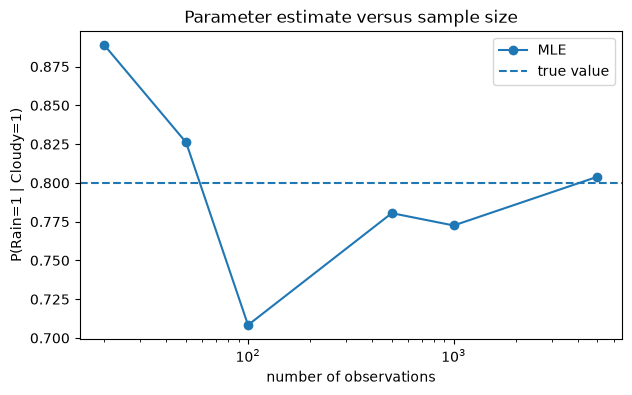

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(sample_sizes, estimates, marker="o", label="MLE")
plt.axhline(0.8, linestyle="--", label="true value")
plt.xscale("log")
plt.xlabel("number of observations")
plt.ylabel("P(Rain=1 | Cloudy=1)")
plt.title("Parameter estimate versus sample size")
plt.legend()
plt.show()

### Ask the LLM to write the parameter-estimation code

Now the engineering task changes.

The LLM receives:

- the known graph structure;
- the fact that a `pandas.DataFrame` called `data` already exists;
- the requirement to estimate CPTs by maximum likelihood.

Again, the statistical estimator is implemented by `pgmpy`. The LLM's role is to construct the correct program.

In [27]:
estimation_prompt = r"""
Write Python code using the current pgmpy API.

A pandas DataFrame named data already exists. Its columns are:
Cloudy, Rain, Sprinkler, WetGrass.
All variables use binary states 0 and 1.

The known Bayesian-network structure is:
Cloudy -> Rain
Cloudy -> Sprinkler
Rain -> WetGrass
Sprinkler -> WetGrass

The CPT parameters are unknown.

Requirements:
- use DiscreteBayesianNetwork;
- use MaximumLikelihoodEstimator;
- estimate all CPTs from data while keeping the graph fixed;
- store the fitted model in a variable called generated_mle_model;
- call generated_mle_model.check_model();
- do not install packages;
- do not read or write files;
- do not use network access;
- return only Python code.
"""

llm_estimation_response = ask_coder(estimation_prompt)
print(llm_estimation_response)

```python
from pgmpy.models import BayesianModel
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import MaximumLikelihoodEstimator

# Define the Bayesian Network structure
model = BayesianModel([('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')])

# Create a list of tuples for each CPD
cpds = [
    (TabularCPD('Cloudy', 2, [[0.5], [0.5]])),
    (TabularCPD('Rain', 2, [[0.4, 0.6], [0.6, 0.4]])),
    (TabularCPD('Sprinkler', 2, [[0.7, 0.3], [0.3, 0.7]])),
    (TabularCPD('WetGrass', 2, [[0.9, 0.1], [0.1, 0.9]]))
]

# Add the CPDs to the model
for cpd in cpds:
    model.add_cpds(cpd)

# Use Maximum Likelihood Estimation to estimate the CPDs
mle = MaximumLikelihoodEstimator(model, data)
generated_mle_model = mle.estimate()

# Check if the model is valid
generated_mle_model.check_model()
```

This code snippet creates a Bayesian network based on the given structure and uses Maximum Likelihood Estimation to estimate the condition

In [28]:
generated_estimation_code = extract_python_code(llm_estimation_response)
print(generated_estimation_code)

problems = basic_generated_code_check(generated_estimation_code)
print("\nBasic check:", problems if problems else "no listed problems")

from pgmpy.models import BayesianModel
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import MaximumLikelihoodEstimator

# Define the Bayesian Network structure
model = BayesianModel([('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')])

# Create a list of tuples for each CPD
cpds = [
    (TabularCPD('Cloudy', 2, [[0.5], [0.5]])),
    (TabularCPD('Rain', 2, [[0.4, 0.6], [0.6, 0.4]])),
    (TabularCPD('Sprinkler', 2, [[0.7, 0.3], [0.3, 0.7]])),
    (TabularCPD('WetGrass', 2, [[0.9, 0.1], [0.1, 0.9]]))
]

# Add the CPDs to the model
for cpd in cpds:
    model.add_cpds(cpd)

# Use Maximum Likelihood Estimation to estimate the CPDs
mle = MaximumLikelihoodEstimator(model, data)
generated_mle_model = mle.estimate()

# Check if the model is valid
generated_mle_model.check_model()

Basic check: no listed problems


#### Review of the generated estimation code

- uses the removed `BayesianModel` class;
- although the prompt says *the CPT parameters are unknown*, the program **hard-codes made-up CPTs** (e.g. `Rain` with values `[[0.4, 0.6], [0.6, 0.4]]`), and declares `Rain`, `Sprinkler`, `WetGrass` **without their parents**, contradicting the graph;
- calls `mle.estimate()`, which does not exist (the method is `get_parameters()`), and never attaches the estimated CPDs to a model;
- it does at least use the supplied `data` (this time it does not redefine it).

So even a program that "uses `MaximumLikelihoodEstimator`" by name does not implement maximum-likelihood estimation on the fixed graph.

#### Execute only after inspection

The generated code should use the provided DataFrame rather than inventing new data.

In [29]:
# Inspected (see the review above). The code uses the removed BayesianModel class, hard-codes
# made-up CPTs and calls a non-existent .estimate() method. We run it only to record the outcome.
APPROVE_ESTIMATION_CODE = True

generated_estimation_namespace = {
    "data": data_1000.copy(),
}

if APPROVE_ESTIMATION_CODE:
    problems = basic_generated_code_check(generated_estimation_code)

    if problems:
        raise RuntimeError(f"Generated code did not pass basic checks: {problems}")

    estimation_exec_error = try_execute(generated_estimation_code, generated_estimation_namespace)
    if estimation_exec_error is None:
        print("Generated estimation code executed.")
    else:
        print("Generated estimation code NOT accepted ->", estimation_exec_error)
else:
    print("Generated code NOT executed. Inspect it first, then approve it.")

Generated estimation code NOT accepted -> ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)


#### Compare the LLM-generated fitted model with the trusted fit

For the same data and the same maximum-likelihood estimator, the fitted CPTs should agree numerically.

In [30]:
def cpd_value_map(model):
    """Flatten CPD arrays into a dictionary for easy numerical comparison."""
    result = {}

    for cpd in model.get_cpds():
        result[cpd.variable] = np.asarray(cpd.values, dtype=float)

    return result


def compare_models(model_a, model_b):
    a = cpd_value_map(model_a)
    b = cpd_value_map(model_b)

    variables = sorted(a)
    rows = []

    for variable in variables:
        diff = np.max(np.abs(a[variable] - b[variable]))
        rows.append({
            "variable": variable,
            "max absolute difference": diff,
        })

    return pd.DataFrame(rows)


if APPROVE_ESTIMATION_CODE and estimation_exec_error is None:
    generated_mle_model = generated_estimation_namespace["generated_mle_model"]

    assert generated_mle_model.check_model()
    display(compare_models(mle_model_1000, generated_mle_model))
elif APPROVE_ESTIMATION_CODE:
    print("The first LLM attempt was not accepted:", estimation_exec_error)
    print("See the repair loop below.")
else:
    print("Run after approving the LLM-generated estimation code.")

The first LLM attempt was not accepted: ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)
See the repair loop below.


#### Validator and repair loop for the estimation code

The estimation validator checks that:

- the graph was kept fixed (same nodes and edges);
- the supplied `data` object was not replaced;
- every fitted CPT equals the trusted MLE fit on the *same* data (`compare_models`).

In [31]:
def make_estimation_namespace():
    return {"data": data_1000.copy()}


def make_estimation_validator(trusted_model, source_data, result_name):
    def validator(ns):
        assert result_name in ns, f"variable {result_name} was not created"
        model = ns[result_name]
        check_structure(model)
        assert model.check_model(), "check_model() returned False"
        assert isinstance(ns.get("data"), pd.DataFrame) and ns["data"].equals(source_data), \
            "the provided DataFrame `data` was modified or replaced"
        diffs = compare_models(trusted_model, model)
        worst = float(diffs["max absolute difference"].max())
        assert worst < 1e-10, f"fitted CPTs differ from the trusted fit: {diffs.to_dict('records')}"
        return {"structure": "PASS", "data untouched": "PASS", "max CPT difference": worst}
    return validator


validate_mle_namespace = make_estimation_validator(mle_model_1000, data_1000, "generated_mle_model")

repaired_estimation_code, repaired_estimation_ns, estimation_history = repair_loop(
    estimation_prompt,
    generated_estimation_code,
    make_namespace=make_estimation_namespace,
    validator=validate_mle_namespace,
)
display(history_table(estimation_history))
print("\nFinal candidate:\n")
print(repaired_estimation_code)

--- round 0: FAIL
    ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)
    new candidate generated (26 lines)
--- round 1: FAIL
    AttributeError: 'list' object has no attribute 'shape'
    new candidate generated (26 lines)
--- round 2: FAIL
    AttributeError: 'list' object has no attribute 'shape'


,round,status,error
0,0,FAIL,ImportError: cannot import name 'BayesianModel...
1,1,FAIL,AttributeError: 'list' object has no attribute...
2,2,FAIL,AttributeError: 'list' object has no attribute...



Final candidate:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import MaximumLikelihoodEstimator

# Define the Bayesian Network structure
edges = [("Cloudy", "Rain"), ("Cloudy", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass")]
model = DiscreteBayesianNetwork(edges)

# Create a list of tuples for each CPD
cpds = [
    (TabularCPD('Cloudy', 2, [[0.5], [0.5]])),
    (TabularCPD('Rain', 2, [[0.4, 0.6], [0.6, 0.4]])),
    (TabularCPD('Sprinkler', 2, [[0.7, 0.3], [0.3, 0.7]])),
    (TabularCPD('WetGrass', 2, [[0.9, 0.1], [0.1, 0.9]]))
]

# Add the CPDs to the model
for cpd in cpds:
    model.add_cpds(cpd)

# Use Maximum Likelihood Estimation to estimate the CPDs
mle = MaximumLikelihoodEstimator(model, data)
generated_mle_model = mle.estimate()

# Check if the model is valid
generated_mle_model.check_model()


In [32]:
human_revised_estimation_code = r"""
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator

generated_mle_model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"), ("Cloudy", "Sprinkler"),
    ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
])
generated_mle_model.add_cpds(
    *MaximumLikelihoodEstimator(generated_mle_model, data).get_parameters()
)
generated_mle_model.check_model()
"""

ns = make_estimation_namespace()
print("execution error:", try_execute(human_revised_estimation_code, ns))
print(validate_mle_namespace(ns))
display(compare_models(mle_model_1000, ns["generated_mle_model"]))

execution error: None
{'structure': 'PASS', 'data untouched': 'PASS', 'max CPT difference': 0.0}


,variable,max absolute difference
0,Cloudy,0.0
1,Rain,0.0
2,Sprinkler,0.0
3,WetGrass,0.0


### Sparse data and Bayesian parameter estimation

Maximum likelihood uses the observed counts directly.

With a small dataset, some parent-state configurations can be rare or even absent. This can produce unstable estimates or probabilities equal to 0 or 1 simply because the sample is small.

A Bayesian estimator adds prior pseudo-counts.

For a Dirichlet prior, the posterior parameter estimate can be viewed conceptually as

$$
\text{posterior counts}
=
\text{observed counts}
+
\text{prior pseudo-counts}.
$$

This is not a claim that one estimator is always better. It is a different modelling assumption that can regularise estimates when data are sparse.

In [33]:
from pgmpy.parameter_estimator import (
    DiscreteMLE,
    DiscreteBayesianEstimator,
)

data_small = reference_model.simulate(
    n_samples=30,
    seed=11,
    show_progress=False,
)

mle_small = make_empty_structure()
mle_small.fit(
    data_small,
    estimator=DiscreteMLE(),
)

bayes_small = make_empty_structure()
bayes_small.fit(
    data_small,
    estimator=DiscreteBayesianEstimator(
        prior_type="BDeu",
        equivalent_sample_size=10,
    ),
)

print("MLE Rain CPD")
print(mle_small.get_cpds("Rain"))

print("\nBayesian Rain CPD")
print(bayes_small.get_cpds("Rain"))

MLE Rain CPD
+---------+---------------------+---------------------+
| Cloudy  | Cloudy(0)           | Cloudy(1)           |
+---------+---------------------+---------------------+
| Rain(0) | 0.9473684210526315  | 0.09090909090909091 |
+---------+---------------------+---------------------+
| Rain(1) | 0.05263157894736842 | 0.9090909090909091  |
+---------+---------------------+---------------------+

Bayesian Rain CPD
+---------+---------------------+-----------+
| Cloudy  | Cloudy(0)           | Cloudy(1) |
+---------+---------------------+-----------+
| Rain(0) | 0.8541666666666666  | 0.21875   |
+---------+---------------------+-----------+
| Rain(1) | 0.14583333333333334 | 0.78125   |
+---------+---------------------+-----------+


#### Compare the small-sample estimates

The BDeu estimate incorporates a prior equivalent sample size.

We should interpret the difference scientifically:

- MLE reflects the empirical frequencies directly;
- Bayesian estimation combines data with the specified prior.

The prior is part of the model and should not be hidden as an implementation detail.

In [34]:
def rain_c1_probability(model):
    return float(model.get_cpds("Rain").values[1, 1])

comparison = pd.DataFrame({
    "method": ["True parameter", "MLE, N=30", "BDeu, N=30"],
    "P(Rain=1 | Cloudy=1)": [
        0.8,
        rain_c1_probability(mle_small),
        rain_c1_probability(bayes_small),
    ],
})

comparison

,method,P(Rain=1 | Cloudy=1)
0,True parameter,0.800000
1,"MLE, N=30",0.909091
2,"BDeu, N=30",0.781250


### Ask the LLM to revise MLE code to Bayesian estimation

This is a useful coding-assistant task because we already know the desired statistical change.

The LLM is asked to revise the implementation, while we remain responsible for checking whether the generated code actually uses the requested prior.

In [35]:
bayesian_prompt = r"""
A pandas DataFrame named data already exists with binary columns:
Cloudy, Rain, Sprinkler, WetGrass.

The known Bayesian-network structure is:
Cloudy -> Rain
Cloudy -> Sprinkler
Rain -> WetGrass
Sprinkler -> WetGrass

Write Python code using the current pgmpy API to estimate all CPTs with BayesianEstimator.
Use:
prior_type="BDeu"
equivalent_sample_size=10

Requirements:
- keep the graph fixed;
- store the fitted model in generated_bayes_model;
- call generated_bayes_model.check_model();
- do not install packages;
- do not read or write files;
- do not use network access;
- return only Python code.
"""

llm_bayesian_response = ask_coder(bayesian_prompt)
print(llm_bayesian_response)

```python
from pgmpy.estimators import BayesianEstimator
import pandas as pd

# Load your data into a pandas DataFrame
data = pd.read_csv('your_data.csv')  # Replace 'your_data.csv' with your actual file path

# Create a BayesianEstimator object
estimator = BayesianEstimator(data, ['Cloudy', 'Rain', 'Sprinkler', 'WetGrass'])

# Fit the model with BDeu prior and equivalent sample size of 10
generated_bayes_model = estimator.fit(prior_type="BDeu", equivalent_sample_size=10)

# Check if the model is valid
generated_bayes_model.check_model()
```

This code snippet loads the data from a CSV file, creates a BayesianEstimator object with the specified prior type and equivalent sample size, fits the model to the data, checks the model's validity, and stores the fitted model in `generated_bayes_model`.


In [36]:
generated_bayesian_code = extract_python_code(llm_bayesian_response)
print(generated_bayesian_code)

problems = basic_generated_code_check(generated_bayesian_code)
print("\nBasic check:", problems if problems else "no listed problems")

from pgmpy.estimators import BayesianEstimator
import pandas as pd

# Load your data into a pandas DataFrame
data = pd.read_csv('your_data.csv')  # Replace 'your_data.csv' with your actual file path

# Create a BayesianEstimator object
estimator = BayesianEstimator(data, ['Cloudy', 'Rain', 'Sprinkler', 'WetGrass'])

# Fit the model with BDeu prior and equivalent sample size of 10
generated_bayes_model = estimator.fit(prior_type="BDeu", equivalent_sample_size=10)

# Check if the model is valid
generated_bayes_model.check_model()

Basic check: no listed problems


#### Inspect, execute and validate the Bayesian-estimation code

Inspection already shows three problems: the code **reads a CSV file** (explicitly forbidden, and it would discard the provided `data`), it passes a list of column names where pgmpy expects a model, and it never builds the fixed graph. The stricter static check catches the file access before anything runs.

For validation we give the generated code the small dataset `data_small` (N = 30) and compare its CPTs with the trusted BDeu fit `bayes_small` on the same data. We also run a **prior-sensitivity check**: a model fitted with the MLE or with a different `equivalent_sample_size` must *fail* this validator, otherwise the test would not really be checking that the requested prior was used.

In [37]:
print("Stricter check:", stricter_generated_code_check(generated_bayesian_code) or "no listed problems")

validate_bayes_namespace = make_estimation_validator(bayes_small, data_small, "generated_bayes_model")

# The validator must be able to tell the priors apart.
for label, est in [("MLE", DiscreteMLE()),
                   ("BDeu, ESS=5", DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=5)),
                   ("BDeu, ESS=10", DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))]:
    m = make_empty_structure()
    m.fit(data_small, estimator=est)
    try:
        validate_bayes_namespace({"data": data_small.copy(), "generated_bayes_model": m})
        print(f"{label:13s} -> accepted")
    except AssertionError:
        print(f"{label:13s} -> rejected")

Stricter check: ["Overwrites the provided variable 'data'", 'Suspicious attribute call (file/system access?): .read_csv(...)']


MLE           -> rejected


BDeu, ESS=5   -> rejected
BDeu, ESS=10  -> accepted


In [38]:
repaired_bayesian_code, repaired_bayesian_ns, bayesian_history = repair_loop(
    bayesian_prompt,
    generated_bayesian_code,
    make_namespace=lambda: {"data": data_small.copy()},
    validator=validate_bayes_namespace,
)
display(history_table(bayesian_history))
print("\nFinal candidate:\n")
print(repaired_bayesian_code)

--- round 0: FAIL
    Rejected by static check: Overwrites the provided variable 'data'; Suspicious attribute call (file/system access?): .read_csv(...)
    new candidate generated (55 lines)
--- round 1: FAIL
    Rejected by static check: Overwrites the provided variable 'data'; Suspicious attribute call (file/system access?): .read_csv(...)
    new candidate generated (56 lines)
--- round 2: FAIL
    Rejected by static check: Overwrites the provided variable 'data'; Suspicious attribute call (file/system access?): .read_csv(...)


,round,status,error
0,0,FAIL,Rejected by static check: Overwrites the provi...
1,1,FAIL,Rejected by static check: Overwrites the provi...
2,2,FAIL,Rejected by static check: Overwrites the provi...



Final candidate:

import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# Define the Bayesian network structure
edges = [("Cloudy", "Rain"), ("Cloudy", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass")]
bn = DiscreteBayesianNetwork(edges)

# Load your data into a pandas DataFrame
data = pd.read_csv('your_data.csv')  # Replace 'your_data.csv' with your actual file path

# Create CPDs for each variable based on the data
cloudy_cpd = TabularCPD(
    "Cloudy",
    2,
    [[0.5, 0.5]],
    evidence=None,
    evidence_card=None
)

rain_cpd = TabularCPD(
    "Rain",
    2,
    [[0.4, 0.6],
     [0.3, 0.7]],
    evidence=("Cloudy",),
    evidence_card=(2,)
)

sprinkler_cpd = TabularCPD(
    "Sprinkler",
    2,
    [[0.8, 0.2],
     [0.2, 0.8]],
    evidence=("Cloudy",),
    evidence_card=(2,)
)

wet_grass_cpd = TabularCPD(
    "WetGrass",
    2,
    [[0.9, 0.1],
     [0.1,

In [39]:
human_revised_bayesian_code = r"""
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator

generated_bayes_model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"), ("Cloudy", "Sprinkler"),
    ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
])
generated_bayes_model.add_cpds(
    *BayesianEstimator(generated_bayes_model, data).get_parameters(
        prior_type="BDeu",
        equivalent_sample_size=10,
    )
)
generated_bayes_model.check_model()
"""

ns = {"data": data_small.copy()}
print("execution error:", try_execute(human_revised_bayesian_code, ns))
print(validate_bayes_namespace(ns))
print(ns["generated_bayes_model"].get_cpds("Rain"))

execution error: None
{'structure': 'PASS', 'data untouched': 'PASS', 'max CPT difference': 0.0}
+---------+---------------------+-----------+
| Cloudy  | Cloudy(0)           | Cloudy(1) |
+---------+---------------------+-----------+
| Rain(0) | 0.8541666666666666  | 0.21875   |
+---------+---------------------+-----------+
| Rain(1) | 0.14583333333333334 | 0.78125   |
+---------+---------------------+-----------+


### A deliberately broken Bayesian network

Validation matters even without an LLM.

Here we intentionally create an invalid CPT whose columns do not sum to 1.

The library should reject the model rather than silently using it.

In [40]:
broken_model = DiscreteBayesianNetwork([
    ("Cloudy", "Rain"),
])

cpd_cloudy_ok = TabularCPD(
    variable="Cloudy",
    variable_card=2,
    values=[[0.5], [0.5]],
)

# Invalid: for Cloudy=0, 0.9 + 0.3 = 1.2.
cpd_rain_broken = TabularCPD(
    variable="Rain",
    variable_card=2,
    values=[
        [0.9, 0.2],
        [0.3, 0.8],
    ],
    evidence=["Cloudy"],
    evidence_card=[2],
)

broken_model.add_cpds(cpd_cloudy_ok, cpd_rain_broken)

try:
    broken_model.check_model()
except Exception as error:
    print("Validation caught the problem:")
    print(type(error).__name__ + ":", error)

Validation caught the problem:
ValueError: Sum or integral of conditional probabilities for node Rain is not equal to 1.


### A subtler failure: valid numbers, wrong semantics

Some mistakes are harder.

Imagine the four WetGrass probabilities are supplied in the wrong parent-state order.

Every column can still sum to 1, so `check_model()` may accept the CPD. Yet the model can represent the wrong distribution.

This is why we also need semantic tests such as known queries or independently calculated probabilities.

In [41]:
wrong_semantics_model = build_reference_model()

# Remove the correct WetGrass CPD.
wrong_semantics_model.remove_cpds(
    wrong_semantics_model.get_cpds("WetGrass")
)

# Deliberately permute the probabilities for the parent configurations.
wrong_wetgrass = TabularCPD(
    variable="WetGrass",
    variable_card=2,
    values=[
        [0.99, 0.10, 0.01, 0.10],
        [0.01, 0.90, 0.99, 0.90],
    ],
    evidence=["Rain", "Sprinkler"],
    evidence_card=[2, 2],
)

wrong_semantics_model.add_cpds(wrong_wetgrass)

print("check_model():", wrong_semantics_model.check_model())

wrong_inference = VariableElimination(wrong_semantics_model)
wrong_posterior = wrong_inference.query(
    ["Rain"],
    evidence={"WetGrass": 1},
    show_progress=False,
)

print("Correct posterior:", posterior_rain.values[1])
print("Wrong posterior  :", wrong_posterior.values[1])

check_model(): True
Correct posterior: 0.7047692307692307
Wrong posterior  : 0.7172952268709487


Our CPT-level validator from above is exactly the kind of semantic test that catches this: `check_model()` accepts the permuted model, but the specification check does not.

In [42]:
try:
    check_cpts_against_spec(wrong_semantics_model)
    print("NOT caught (bad test!)")
except AssertionError as error:
    print("Semantic validator caught it:\n ", error)

Semantic validator caught it:
  CPT entries differ from the specification: P(WetGrass=1 | {'Rain': 1, 'Sprinkler': 0}) = 0.99, spec says 0.9; P(WetGrass=0 | {'Rain': 1, 'Sprinkler': 0}) = 0.01, spec says 0.1; P(WetGrass=1 | {'Rain': 1, 'Sprinkler': 1}) = 0.9, spec says 0.99; P(WetGrass=0 | {'Rain': 1, 'Sprinkler': 1}) = 0.1, spec says 0.01


**This is the central science-engineering lesson:**

```text
Program runs
    !=
Probabilistic model is correct
    !=
Scientific assumptions are appropriate
```

The LLM can accelerate implementation, but it does not remove the need to understand the model.

### Turn validation into reusable tests

Instead of checking things manually every time, encode important expectations as tests.

In [43]:
def test_reference_model():
    model = build_reference_model()

    assert model.check_model()

    assert set(model.nodes()) == {
        "Cloudy", "Rain", "Sprinkler", "WetGrass"
    }

    assert set(model.edges()) == {
        ("Cloudy", "Rain"),
        ("Cloudy", "Sprinkler"),
        ("Rain", "WetGrass"),
        ("Sprinkler", "WetGrass"),
    }

    infer = VariableElimination(model)
    posterior = infer.query(
        ["Rain"],
        evidence={"WetGrass": 1},
        show_progress=False,
    )

    assert np.isclose(
        posterior.values[1],
        posterior_by_enumeration,
        atol=1e-10,
    )


test_reference_model()
print("All reference tests passed.")

All reference tests passed.


In [44]:
def test_wrong_semantics_is_detected():
    try:
        check_cpts_against_spec(wrong_semantics_model)
    except AssertionError:
        return
    raise AssertionError("permuted WetGrass CPD was not detected")


def test_human_revised_programs():
    ns = {}
    assert try_execute(human_revised_inference_code, ns) is None
    validate_inference_namespace(ns)

    ns = make_estimation_namespace()
    assert try_execute(human_revised_estimation_code, ns) is None
    validate_mle_namespace(ns)

    ns = {"data": data_small.copy()}
    assert try_execute(human_revised_bayesian_code, ns) is None
    validate_bayes_namespace(ns)


def test_static_check_rejects_file_access():
    assert stricter_generated_code_check("import pandas as pd\ndata = pd.read_csv('x.csv')")


for test in [test_reference_model, test_wrong_semantics_is_detected,
             test_human_revised_programs, test_static_check_rejects_file_access]:
    test()
    print("PASS", test.__name__)

PASS test_reference_model
PASS test_wrong_semantics_is_detected


PASS test_human_revised_programs
PASS test_static_check_rejects_file_access


### What exactly did the LLM contribute?

The notebook contains several different computational roles.

| Task | Component responsible |
|---|---|
| Interpret the natural-language programming request | LLM |
| Generate candidate Python code | LLM |
| Represent the Bayesian network | `pgmpy` |
| Check local BN consistency | `pgmpy.check_model()` |
| Perform exact inference | `VariableElimination` |
| Estimate CPTs from data | `MaximumLikelihoodEstimator` / `BayesianEstimator` |
| Decide whether generated code is acceptable | validation logic + human |
| Decide whether the statistical assumptions make sense | human / scientific reasoning |

This separation is important.

An LLM coding assistant can be useful without being treated as the source of probabilistic truth.

### An engineering view of the whole notebook

The complete loop is

```text
Bayesian-network theory
        |
        v
Natural-language specification
        |
        v
      LLM
        |
        v
Generated Python code
        |
        v
Static inspection / approval
        |
        v
      pgmpy
        |
        v
Inference or parameter estimation
        |
        v
Validation against mathematical expectations
        |
        +---- pass ----> use result
        |
        +---- fail ----> revise specification/code
```

The important point is that AI engineering does not mean abandoning the scientific model.

It means building a dependable software process around it.

### HW exercise: change the query

Without changing the network, ask the LLM to generate code for each query:

$$
P(S=1\mid W=1),
$$

$$
P(C=1\mid W=1),
$$

and

$$
P(R=1\mid W=1,S=0).
$$

Before running the generated code:

- identify the query variable;
- identify the evidence;
- predict qualitatively whether the posterior should increase or decrease;
- inspect the generated code;
- compare it with a trusted `VariableElimination` call.

In [45]:
# Trusted query examples for the exercise.
trusted_infer = VariableElimination(reference_model)

q_s = trusted_infer.query(
    ["Sprinkler"],
    evidence={"WetGrass": 1},
    show_progress=False,
)

q_c = trusted_infer.query(
    ["Cloudy"],
    evidence={"WetGrass": 1},
    show_progress=False,
)

q_r_given_w_s0 = trusted_infer.query(
    ["Rain"],
    evidence={"WetGrass": 1, "Sprinkler": 0},
    show_progress=False,
)

print("P(Sprinkler=1 | WetGrass=1) =", q_s.values[1])
print("P(Cloudy=1 | WetGrass=1) =", q_c.values[1])
print("P(Rain=1 | WetGrass=1, Sprinkler=0) =", q_r_given_w_s0.values[1])

P(Sprinkler=1 | WetGrass=1) = 0.4278461538461539
P(Cloudy=1 | WetGrass=1) = 0.5746153846153845
P(Rain=1 | WetGrass=1, Sprinkler=0) = 0.9922022048937886


## HW solution: change the query

### Step 1 — identify query, evidence and predict (before running anything)

Prior marginals, from the specification:

$$
P(S=1)=0.5\cdot0.5+0.5\cdot0.1=0.30,\qquad P(C=1)=0.5,\qquad P(R=1\mid W=1)\approx0.705\ \text{(computed above)}.
$$

| Query | Query variable | Evidence | Compare with | Qualitative prediction | Reasoning |
|---|---|---|---|---|---|
| $P(S=1\mid W=1)$ | Sprinkler | WetGrass = 1 | prior $P(S=1)=0.30$ | **increase** | $S$ is a cause of $W$; observing an effect raises the probability of each of its causes (diagnostic reasoning). But rain is the likelier cause, so it should stay below 0.5. |
| $P(C=1\mid W=1)$ | Cloudy | WetGrass = 1 | prior $P(C=1)=0.5$ | **small increase** | $C$ affects $W$ along two paths with opposite signs: $C\uparrow\Rightarrow R\uparrow$ (wetter) but $C\uparrow\Rightarrow S\downarrow$ (drier). $P(W=1\mid C=1)=0.747 > P(W=1\mid C=0)=0.553$, so the rain path dominates, but the cancellation keeps the effect modest. |
| $P(R=1\mid W=1,S=0)$ | Rain | WetGrass = 1, Sprinkler = 0 | $P(R=1\mid W=1)\approx0.705$ | **strong increase, close to 1** | Explaining away in reverse: the only competing explanation (sprinkler) is ruled out, and $P(W=1\mid R=0,S=0)=0.01$ is tiny, so wet grass is almost only explicable by rain. |

### Step 2 — ask the LLM, one prompt per query

The prompt restates the full network (the LLM has no memory between calls) and names the query and evidence explicitly, with the result variable `generated_query_result`.

In [46]:
NETWORK_SPEC = r"""
Construct this binary discrete Bayesian network with the current pgmpy API:

Edges:
Cloudy -> Rain
Cloudy -> Sprinkler
Rain -> WetGrass
Sprinkler -> WetGrass

Use states 0=False and 1=True.

Probabilities:
P(Cloudy=1) = 0.5
P(Rain=1 | Cloudy=0) = 0.2
P(Rain=1 | Cloudy=1) = 0.8
P(Sprinkler=1 | Cloudy=0) = 0.5
P(Sprinkler=1 | Cloudy=1) = 0.1
P(WetGrass=1 | Rain=0, Sprinkler=0) = 0.01
P(WetGrass=1 | Rain=0, Sprinkler=1) = 0.90
P(WetGrass=1 | Rain=1, Sprinkler=0) = 0.90
P(WetGrass=1 | Rain=1, Sprinkler=1) = 0.99
"""


def make_query_prompt(query_var, evidence):
    evidence_text = ", ".join(f"{k}={v}" for k, v in evidence.items())
    return (
        "Write Python code using the current pgmpy API.\n"
        + NETWORK_SPEC
        + f"""
Requirements:
- use DiscreteBayesianNetwork and TabularCPD;
- create a variable called generated_model;
- add all CPDs and call generated_model.check_model();
- use VariableElimination;
- compute the posterior distribution P({query_var} | {evidence_text});
- store that query result (the DiscreteFactor returned by the query) in generated_query_result;
- do not install packages;
- do not read or write files;
- do not use network access;
- return only Python code.
"""
    )


HW_QUERIES = [
    ("Sprinkler", {"WetGrass": 1}),
    ("Cloudy", {"WetGrass": 1}),
    ("Rain", {"WetGrass": 1, "Sprinkler": 0}),
]

hw_prompts = {}
hw_first_codes = {}
for query_var, evidence in HW_QUERIES:
    key = (query_var, tuple(evidence.items()))
    hw_prompts[key] = make_query_prompt(query_var, evidence)
    hw_first_codes[key] = extract_python_code(ask_coder(hw_prompts[key], max_new_tokens=800))
    print("=" * 80)
    print(f"LLM code for P({query_var}=1 | {evidence})")
    print("=" * 80)
    print(hw_first_codes[key])
    print("\nStricter static check:", stricter_generated_code_check(hw_first_codes[key]) or "no listed problems")

LLM code for P(Sprinkler=1 | {'WetGrass': 1})
from pgmpy.models import BayesianModel
from pgmpy.factors.discrete import TabularCPD

# Define the model
generated_model = BayesianModel()

# Add nodes
generated_model.add_nodes_from(['Cloudy', 'Rain', 'Sprinkler', 'WetGrass'])

# Add edges
generated_model.add_edges_from([('Cloudy', 'Rain'), ('Cloudy', 'Sprinkler'),
                              ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')])

# Define CPDs for each node
cloudy_cpd = TabularCPD('Cloudy', 2, [[0.5], [0.5]])
rain_given_cloudy_cpd = TabularCPD('Rain', 2, [[0.2, 0.8], [0.8, 0.2]], evidence=['Cloudy'], evidence_card=[2])
sprinkler_given_cloudy_cpd = TabularCPD('Sprinkler', 2, [[0.5, 0.1], [0.1, 0.5]], evidence=['Cloudy'], evidence_card=[2])
wet_grass_given_rain_sprinkler_cpd = TabularCPD('WetGrass', 2, 
                                                 [[0.01, 0.90, 0.90, 0.01],
                                                  [0.90, 0.01, 0.99, 0.90]],
                       

### Step 3 — trusted answers, including an independent oracle

`VariableElimination` on the trusted model gives the reference values (computed in the cell above). We also compute every query by brute-force enumeration of the 16 joint assignments, re-using the independent factor functions `p_cloudy`, `p_rain`, `p_sprinkler`, `p_wetgrass`.

In [47]:
def enumerate_posterior(query_var, evidence):
    names = ["Cloudy", "Rain", "Sprinkler", "WetGrass"]
    num = den = 0.0
    for c, r, s, w in itertools.product([0, 1], repeat=4):
        a = dict(zip(names, (c, r, s, w)))
        if any(a[k] != v for k, v in evidence.items()):
            continue
        joint = p_cloudy(c) * p_rain(r, c) * p_sprinkler(s, c) * p_wetgrass(w, r, s)
        den += joint
        if a[query_var] == 1:
            num += joint
    return num / den


prior_reference = {
    ("Sprinkler", (("WetGrass", 1),)): ("P(S=1)", enumerate_posterior("Sprinkler", {})),
    ("Cloudy", (("WetGrass", 1),)): ("P(C=1)", enumerate_posterior("Cloudy", {})),
    ("Rain", (("WetGrass", 1), ("Sprinkler", 0))): ("P(R=1|W=1)", enumerate_posterior("Rain", {"WetGrass": 1})),
}
predictions = {"Sprinkler": "increase", "Cloudy": "small increase", "Rain": "strong increase"}

trusted_rows = []
for query_var, evidence in HW_QUERIES:
    key = (query_var, tuple(evidence.items()))
    ve = float(trusted_infer.query([query_var], evidence=evidence, show_progress=False).get_value(**{query_var: 1}))
    en = enumerate_posterior(query_var, evidence)
    base_label, base = prior_reference[key]
    trusted_rows.append({
        "query": f"P({query_var}=1 | {', '.join(f'{k}={v}' for k, v in evidence.items())})",
        "VariableElimination": ve, "enumeration": en, "|VE - enum|": abs(ve - en),
        "baseline": f"{base_label} = {base:.4f}",
        "predicted": predictions[query_var],
        "observed change": f"{ve - base:+.4f}",
    })
    assert np.isclose(ve, en, atol=1e-12)

trusted_table = pd.DataFrame(trusted_rows)
trusted_table

,query,VariableElimination,enumeration,|VE - enum|,baseline,predicted,observed change
0,P(Sprinkler=1 | WetGrass=1),0.427846,0.427846,5.551115e-17,P(S=1) = 0.3000,increase,+0.1278
1,P(Cloudy=1 | WetGrass=1),0.574615,0.574615,2.220446e-16,P(C=1) = 0.5000,small increase,+0.0746
2,"P(Rain=1 | WetGrass=1, Sprinkler=0)",0.992202,0.992202,0.000000e+00,P(R=1|W=1) = 0.7048,strong increase,+0.2874


All three predictions are confirmed: $P(S=1\mid W=1)$ rises from 0.30 to about 0.43; $P(C=1\mid W=1)$ rises only slightly, from 0.50 to about 0.57, because the two causal paths from Cloudy partly cancel; and ruling out the sprinkler pushes $P(R=1\mid W=1,S=0)$ from 0.70 to about 0.99.

### Step 4 — execute and validate the LLM code, repairing when necessary

In [48]:
def make_query_validator(query_var, evidence):
    expected = enumerate_posterior(query_var, evidence)

    def validator(ns):
        assert "generated_model" in ns, "variable generated_model was not created"
        assert "generated_query_result" in ns, "variable generated_query_result was not created"
        model, result = ns["generated_model"], ns["generated_query_result"]
        check_structure(model)
        assert model.check_model(), "check_model() returned False"
        check_cpts_against_spec(model)
        assert hasattr(result, "variables"), f"generated_query_result is a {type(result).__name__}, expected a DiscreteFactor"
        assert list(result.variables) == [query_var], \
            f"query result is over {list(result.variables)}, expected [{query_var!r}] (wrong query variable)"
        value = float(result.get_value(**{query_var: 1}))
        assert np.isclose(value, expected, atol=1e-10), \
            f"P({query_var}=1 | {evidence}) = {value}, trusted value is {expected} (wrong evidence or CPTs?)"
        return {"posterior": value, "trusted": expected, "abs error": abs(value - expected)}

    return validator


hw_results = []
hw_final_codes = {}
for query_var, evidence in HW_QUERIES:
    key = (query_var, tuple(evidence.items()))
    print("#" * 80)
    print(f"# P({query_var}=1 | {evidence})")
    final_code, ns, history = repair_loop(
        hw_prompts[key], hw_first_codes[key], make_namespace=dict,
        validator=make_query_validator(query_var, evidence),
        max_rounds=1,
    )
    hw_final_codes[key] = final_code
    hw_results.append({
        "query": f"P({query_var}=1 | {', '.join(f'{k}={v}' for k, v in evidence.items())})",
        "first attempt": history[0]["status"],
        "first error": (history[0]["error"] or "")[:120],
        "rounds used": len(history) - 1,
        "final status": history[-1]["status"],
        "LLM posterior": float(ns["generated_query_result"].get_value(**{query_var: 1})) if ns else np.nan,
        "trusted": enumerate_posterior(query_var, evidence),
    })

hw_summary = pd.DataFrame(hw_results)
hw_summary

################################################################################
# P(Sprinkler=1 | {'WetGrass': 1})


--- round 0: FAIL
    ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)
    new candidate generated (34 lines)
--- round 1: FAIL
    ValueError: Length of evidence_card doesn't match length of evidence
################################################################################
# P(Cloudy=1 | {'WetGrass': 1})
--- round 0: FAIL
    ImportError: cannot import name 'BayesianModel' from 'pgmpy.models' (C:\Users\USER\AppData\Local\Temp\claude\C--Users-USER-Claude\790ae3ec-601f-4bad-9c07-a8310d4c700b\scratchpad\venv\Lib\site-packages\pgmpy\models\__init__.py)
    new candidate generated (49 lines)
--- round 1: FAIL
    TypeError: Values must be a 2D list/array
################################################################################
# P(Rain=1 | {'WetGrass': 1, 'Sprinkler': 0})
--- round 0: FAIL
    ImportE

,query,first attempt,first error,rounds used,final status,LLM posterior,trusted
0,P(Sprinkler=1 | WetGrass=1),FAIL,ImportError: cannot import name 'BayesianModel...,1,FAIL,NaN,0.427846
1,P(Cloudy=1 | WetGrass=1),FAIL,ImportError: cannot import name 'BayesianModel...,1,FAIL,NaN,0.574615
2,"P(Rain=1 | WetGrass=1, Sprinkler=0)",FAIL,ImportError: cannot import name 'BayesianModel...,1,FAIL,NaN,0.992202


#### Findings from inspecting the LLM's HW programs

- **Query variable and evidence were translated correctly in all three programs** (`Sprinkler | WetGrass=1`, `Cloudy | WetGrass=1`, `Rain | WetGrass=1, Sprinkler=0`). This is the part of the task the prompt changes, and the LLM handled it.
- **The network itself was wrong every time**: the same swapped `Rain` rows, non-normalised `Sprinkler` columns and malformed `WetGrass` CPD as before, plus the removed `BayesianModel` class and the non-existent `model.query`. For $P(C=1\mid W=1)$ the LLM even passed `variable_card=[1]` and one-row CPDs.
- After one round of feedback the API was fixed, but the programs still crashed on the CPD definitions (`evidence_card` length, or 1-D `values`), and none returned a posterior.
- So none of the three LLM programs can be trusted; the correct values come from the validated programs below, and they agree with both `VariableElimination` on the reference model and brute-force enumeration.

### Step 5 — the trusted program for each query

For completeness, the engineer-reviewed program that answers each HW query re-uses the validated `human_revised_inference_code` (which already constructs the correct network) and only changes the query. Each one passes the same validator.

In [49]:
network_only_code = human_revised_inference_code.split("generated_posterior")[0]

for query_var, evidence in HW_QUERIES:
    program = network_only_code + (
        f"generated_query_result = VariableElimination(generated_model).query(\n"
        f"    variables=[{query_var!r}], evidence={evidence!r}, show_progress=False\n)\n"
    )
    ns = {}
    assert try_execute(program, ns) is None
    report = make_query_validator(query_var, evidence)(ns)
    print(f"P({query_var}=1 | {evidence}) = {report['posterior']:.6f}  [validated]")

P(Sprinkler=1 | {'WetGrass': 1}) = 0.427846  [validated]


P(Cloudy=1 | {'WetGrass': 1}) = 0.574615  [validated]
P(Rain=1 | {'WetGrass': 1, 'Sprinkler': 0}) = 0.992202  [validated]


### Classroom exercise: let the LLM explain its generated CPT

Ask the LLM:

> Explain exactly what each column of the WetGrass `TabularCPD` represents when `evidence=["Rain", "Sprinkler"]`. Do not change the code.

Then verify the explanation against the actual library convention and against the probabilities we specified.

This is useful because code generation and code explanation are different tasks, and either can be wrong.

In [50]:
explain_prompt = r"""
Consider this pgmpy code:

wet_grass_cpd = TabularCPD(
    variable="WetGrass",
    variable_card=2,
    values=[
        [0.99, 0.10, 0.10, 0.01],  # WetGrass=0
        [0.01, 0.90, 0.90, 0.99],  # WetGrass=1
    ],
    evidence=["Rain", "Sprinkler"],
    evidence_card=[2, 2],
)

Explain exactly what each column of the WetGrass TabularCPD represents when
evidence=["Rain", "Sprinkler"]. For each of the four columns, state the values of Rain and
Sprinkler and the probability P(WetGrass=1 | Rain, Sprinkler). Do not change the code.
"""

llm_explanation = ask_coder(explain_prompt, max_new_tokens=600)
print(llm_explanation)

The first column of the `TabularCPD` represents the probability that the grass is wet given no rain or sprinkler. The second column represents the probability that the grass is wet given rain but no sprinkler. The third column represents the probability that the grass is wet given sprinkler but no rain. The fourth column represents the probability that the grass is wet given both rain and sprinkler.

For the specific case where `evidence=["Rain", "Sprinkler"]`, the probabilities are as follows:
- P(WetGrass=1 | Rain, Sprinkler) = 0.10
- P(WetGrass=1 | Rain, NoSprinkler) = 0.01
- P(WetGrass=1 | NoRain, Sprinkler) = 0.90
- P(WetGrass=1 | NoRain, NoSprinkler) = 0.99


#### Verify the explanation against the library convention

We do not take the explanation on trust. The cell below asks `pgmpy` itself which parent assignment each column corresponds to (by reshaping the CPD's value array, whose axes are `[WetGrass, Rain, Sprinkler]`) and compares it with the specification. The convention is: columns follow `itertools.product` over the evidence list, so the **last** evidence variable (`Sprinkler`) changes fastest.

In [51]:
wg = reference_model.get_cpds("WetGrass")
print("CPD variables (axis order):", wg.variables)
print("values array shape       :", wg.values.shape)

flat = wg.get_values()  # 2 x 4 matrix exactly as passed to TabularCPD
rows = []
for col, (r, s) in enumerate(itertools.product(range(2), range(2))):
    rows.append({
        "column": col,
        "Rain": r,
        "Sprinkler": s,
        "P(W=1) from column": flat[1, col],
        "P(W=1) via get_value": float(wg.get_value(WetGrass=1, Rain=r, Sprinkler=s)),
        "P(W=1) specification": SPEC_P_TRUE["WetGrass"][(r, s)],
    })
convention = pd.DataFrame(rows)
assert np.allclose(convention["P(W=1) from column"], convention["P(W=1) specification"])
assert np.allclose(convention["P(W=1) via get_value"], convention["P(W=1) specification"])
convention

CPD variables (axis order): ['WetGrass', 'Rain', 'Sprinkler']
values array shape       : (2, 2, 2)


,column,Rain,Sprinkler,P(W=1) from column,P(W=1) via get_value,P(W=1) specification
0,0,0,0,0.01,0.01,0.01
1,1,0,1,0.90,0.90,0.90
2,2,1,0,0.90,0.90,0.90
3,3,1,1,0.99,0.99,0.99


In [52]:
# Reviewer's transcription of the claims in the LLM explanation printed above
# (the response is fixed: greedy decoding, stored in llm_responses.json).
llm_claimed_column_meaning = {0: (0, 0),   # "no rain or sprinkler"
                              1: (1, 0),   # "rain but no sprinkler"
                              2: (0, 1),   # "sprinkler but no rain"
                              3: (1, 1)}   # "both rain and sprinkler"
llm_claimed_p_wet = {(1, 1): 0.10, (1, 0): 0.01, (0, 1): 0.90, (0, 0): 0.99}

rows = []
for col, (r, s_) in enumerate(itertools.product(range(2), range(2))):
    rows.append({
        "column": col,
        "true (Rain, Sprinkler)": (r, s_),
        "LLM says": llm_claimed_column_meaning[col],
        "column meaning correct": llm_claimed_column_meaning[col] == (r, s_),
        "true P(W=1|R,S)": SPEC_P_TRUE["WetGrass"][(r, s_)],
        "LLM's P(W=1|R,S)": llm_claimed_p_wet[(r, s_)],
        "probability correct": bool(np.isclose(llm_claimed_p_wet[(r, s_)], SPEC_P_TRUE["WetGrass"][(r, s_)])),
    })
explanation_check = pd.DataFrame(rows)
explanation_check

,column,"true (Rain, Sprinkler)",LLM says,column meaning correct,"true P(W=1|R,S)","LLM's P(W=1|R,S)",probability correct
0,0,"(0, 0)","(0, 0)",True,0.01,0.99,False
1,1,"(0, 1)","(1, 0)",False,0.90,0.90,True
2,2,"(1, 0)","(0, 1)",False,0.90,0.01,False
3,3,"(1, 1)","(1, 1)",True,0.99,0.10,False


**Verdict on the explanation.** The LLM got the first and last columns right but **swapped the two middle columns**: it described column 1 as "rain but no sprinkler", whereas pgmpy's convention (last evidence variable changes fastest) makes column 1 $(R=0,S=1)$. Its numerical list is worse: only $P(W=1\mid R=0,S=1)=0.90$ is right; it reports $P(W=1\mid R=1,S=1)=0.10$ and $P(W=1\mid R=0,S=0)=0.99$, which reverses the meaning of the table. The explanation is fluent and confident but wrong, which is exactly why we verify it against the library (`get_value`) and the specification rather than trusting it. Code generation and code explanation are separate tasks, and here both failed.

### Classroom exercise: estimate from different datasets

Generate several datasets using different random seeds.

For each one:

- fit an MLE model;
- record $\widehat{P}(R=1\mid C=1)$;
- compare it with the true value $0.8$;
- ask the LLM to explain why different datasets produce different estimates.

The correct scientific explanation should refer to **sampling variability**, not to the LLM or to `pgmpy` being inconsistent.

In [53]:
from pgmpy.parameter_estimator import DiscreteMLE

rows = []

for seed in [1, 2, 3, 4, 5]:
    data = reference_model.simulate(
        n_samples=100,
        seed=seed,
        show_progress=False,
    )

    fitted = make_empty_structure()

    fitted.fit(
        data,
        estimator=DiscreteMLE(),
    )

    n_cloudy = int((data["Cloudy"] == 1).sum())
    estimate = rain_c1_probability(fitted)
    rows.append({
        "seed": seed,
        "N(Cloudy=1)": n_cloudy,
        "estimate": estimate,
        "true value": 0.8,
        "absolute error": abs(estimate - 0.8),
        # approximate standard error of a proportion estimated from N(Cloudy=1) rows
        "approx. std. error": np.sqrt(0.8 * 0.2 / n_cloudy),
    })

seed_table = pd.DataFrame(rows)
seed_table

,seed,N(Cloudy=1),estimate,true value,absolute error,approx. std. error
0,1,49,0.693878,0.8,0.106122,0.057143
1,2,44,0.795455,0.8,0.004545,0.060302
2,3,47,0.744681,0.8,0.055319,0.058346
3,4,56,0.767857,0.8,0.032143,0.053452
4,5,49,0.795918,0.8,0.004082,0.057143


The estimates differ from seed to seed even though the model, the estimator and the code are identical. $\widehat{P}(R=1\mid C=1)$ is a proportion computed from only about $N(C=1)\approx 50$ rows, so its standard deviation is roughly $\sqrt{0.8\cdot0.2/50}\approx0.057$; the observed spread is of exactly that size.

To make the sampling-variability explanation quantitative, we repeat the experiment over many seeds for several sample sizes and compare the empirical spread of the estimates with the theoretical $\sqrt{p(1-p)/(N\,P(C=1))}$.

,N,mean estimate,bias,empirical std,theoretical std sqrt(p(1-p)/(0.5 N))
0,50,0.777196,-0.022804,0.086018,0.080000
1,100,0.806336,0.006336,0.054971,0.056569
2,500,0.802432,0.002432,0.024460,0.025298
3,2000,0.800545,0.000545,0.012972,0.012649


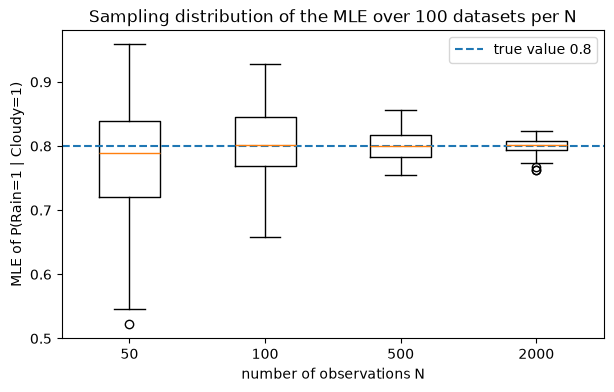

In [54]:
def mle_rain_c1(n, seed):
    d = reference_model.simulate(n_samples=n, seed=seed, show_progress=False)
    m = make_empty_structure()
    m.fit(d, estimator=DiscreteMLE())
    return rain_c1_probability(m)


N_SEEDS = 100
spread_rows = []
all_estimates = {}
for n in [50, 100, 500, 2000]:
    ests = np.array([mle_rain_c1(n, seed) for seed in range(1000, 1000 + N_SEEDS)])
    all_estimates[n] = ests
    spread_rows.append({
        "N": n,
        "mean estimate": ests.mean(),
        "bias": ests.mean() - 0.8,
        "empirical std": ests.std(ddof=1),
        "theoretical std  sqrt(p(1-p)/(0.5 N))": np.sqrt(0.8 * 0.2 / (0.5 * n)),
    })

spread_table = pd.DataFrame(spread_rows)
display(spread_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([all_estimates[n] for n in all_estimates], tick_labels=[str(n) for n in all_estimates])
ax.axhline(0.8, linestyle="--", label="true value 0.8")
ax.set_xlabel("number of observations N")
ax.set_ylabel(r"MLE of P(Rain=1 | Cloudy=1)")
ax.set_title(f"Sampling distribution of the MLE over {N_SEEDS} datasets per N")
ax.legend()
plt.show()

The mean estimate is essentially unbiased at every $N$, and the spread shrinks like $1/\sqrt{N}$, matching the theoretical standard error. The variation is a property of the **data**, not of `pgmpy` or of the code.

#### Ask the LLM to explain the variation

In [55]:
variability_prompt = f"""
I simulated five datasets of 100 samples each (different random seeds) from the same known Bayesian
network, in which the true value of P(Rain=1 | Cloudy=1) is 0.8. For each dataset I fitted the CPTs by
maximum likelihood with pgmpy, keeping the graph fixed. The estimates were:

{seed_table[["seed", "N(Cloudy=1)", "estimate"]].to_string(index=False)}

Over 100 datasets per sample size, the standard deviation of the estimate was:
{spread_table[["N", "empirical std"]].to_string(index=False)}

In a short paragraph, explain why different datasets produce different estimates, and how this
changes with the sample size. Do not write code.
"""

llm_variability_explanation = ask_coder(variability_prompt, max_new_tokens=400)
print(llm_variability_explanation)

The differences in the estimates across different datasets arise due to the inherent randomness in the simulation process. Each dataset is generated independently using a specific random seed, which means that the initial conditions for the Bayesian network are slightly different. This leads to slight variations in the estimated probabilities.

As the sample size increases, the variability in the estimates decreases because there are more data points available to estimate the parameters. In the case of the given dataset sizes, the empirical standard deviations decrease as the sample size increases, indicating that the estimates become more stable and less variable.


In [56]:
# Light-weight check of the explanation: the scientifically correct answer must appeal to
# sampling variability / randomness of finite samples and to sample size, not to software bugs.
text = llm_variability_explanation.lower()
checks = {
    "mentions sampling / random variation": any(k in text for k in ["sampl", "random", "variab", "chance"]),
    "mentions sample size": any(k in text for k in ["sample size", "larger", "more data", "number of samples", "increase"]),
    "blames software (should be False)": any(k in text for k in ["bug", "pgmpy is inconsistent", "library error"]),
}
checks

{'mentions sampling / random variation': True,
 'mentions sample size': True,
 'blames software (should be False)': False}

**Verdict on the explanation.** The LLM correctly attributes the differences to randomness in the finite samples and correctly says the variability shrinks as the sample size grows. One statement is inaccurate: it says the random seed changes "the initial conditions for the Bayesian network". The network and its parameters are identical in every run; only the **sampled data** differ. The precise statement is that $\widehat{P}(R=1\mid C=1)=N(R=1,C=1)/N(C=1)$ is a random variable (a sample proportion), with standard error $\approx\sqrt{p(1-p)/N(C=1)}$, which decreases like $1/\sqrt{N}$. The empirical spreads in the table match this formula.

### Now, where could the system fail?

Potential failure modes include:

- the natural-language specification is ambiguous;
- the LLM uses an obsolete API;
- the LLM reverses a CPT row or parent ordering;
- generated code imports or calls something unintended;
- the code executes but represents the wrong distribution;
- the inference query uses the wrong evidence state;
- the dataset uses a different state encoding from the model;
- sparse data make parameter estimates unstable;
- a prior is introduced without being documented;
- a validation test checks only syntax and misses semantics.

The engineering response is not "trust the LLM more." It is to make the specification, validation, tests, and review process better.

### A compact evaluation rubric for LLM-generated BN code

For each generated program, check:

**Structure**

- correct variables;
- correct directed edges;
- acyclic graph.

**Parameters**

- each CPD is normalized;
- evidence variables are correct;
- parent-state ordering is correct;
- probabilities match the specification.

**Inference**

- correct query variable;
- correct evidence;
- posterior agrees with a trusted implementation or hand calculation.

**Parameter estimation**

- graph structure is not accidentally relearned;
- requested estimator is actually used;
- prior settings are explicit when Bayesian estimation is requested;
- estimates are compared on the same dataset.

**Software safety**

- generated code is inspected before execution;
- unnecessary file/network/system access is disallowed;
- model/library versions are recorded when reproducibility matters.

### The rubric applied to every program in this notebook

LLM: `Qwen/Qwen2.5-Coder-1.5B-Instruct`, greedy decoding, CPU; all responses are stored in `llm_responses.json`.

| Program | Structure | Parameters | Inference / estimation | Software safety | Verdict |
|---|---|---|---|---|---|
| LLM inference code (first attempt) | correct edges, but removed `BayesianModel` class | Rain rows swapped; Sprinkler & WetGrass columns not normalised; `evidence_card=[2]` for 2 parents | right query & evidence, but non-existent `model.query`; no `VariableElimination` | passes static checks | **FAIL** (ImportError) |
| LLM inference code after 2 repair rounds | correct (`DiscreteBayesianNetwork`) | same CPT errors | `VariableElimination` now used correctly | passes | **FAIL** (ValueError; CPT errors confirmed once the crash is patched) |
| LLM MLE code (first attempt + 2 repairs) | parents dropped from the CPDs | invents CPTs although they are unknown | non-existent `.estimate()`; estimator never really fitted | passes | **FAIL** |
| LLM BDeu code (first attempt + 2 repairs) | no graph in the first attempt | repairs hard-code made-up CPTs | prior `BDeu`, ESS = 10 named, but wrong constructor | **reads a CSV file and overwrites `data`** (rejected by the stricter check in every round) | **FAIL** |
| LLM HW query programs (3 queries, 1 repair each) | correct edges | same CPT errors | **query variable & evidence correct in all three** | passes | **FAIL** |
| LLM explanation of the WetGrass CPD | n/a | middle columns swapped; 3 of 4 probabilities wrong | n/a | n/a | **incorrect** |
| LLM explanation of sampling variability | n/a | n/a | correct main idea; one imprecise sentence | n/a | **mostly correct** |
| Human-revised inference / MLE / BDeu programs | PASS | PASS (every CPT entry checked by name) | PASS (posterior error about 2e-16; CPT difference 0.0) | PASS | **PASS** |
| Human-revised HW query programs | PASS | PASS | PASS (match enumeration) | PASS | **PASS** |

### Conclusions

1. **Running is not the same as being correct.** Even when the crash is fixed, the LLM's network encodes a different distribution. Only the semantic tests (CPT-level comparison, enumeration oracle, comparison with a trusted fit on the same data) reveal it; `check_model()` alone is not enough (see the permuted WetGrass CPD).
2. **The small local LLM was useful for the "shape" of the program** (imports, graph, query variable and evidence) but not for the probabilistic content (CPT orientation and parent ordering) or the current pgmpy API. Feedback fixed the API but not the semantics.
3. **Static checks must look beyond bare-name calls.** The LLM's BDeu program read a CSV file through `pd.read_csv` and replaced the supplied data; the notebook's basic check did not notice, while the stricter check did.
4. **The human stays responsible**: for the specification, for the prior (BDeu, ESS = 10, and a test that distinguishes it from other priors), and for accepting code only after it passes the tests.

### Recap

The Bayesian network remains the scientific object:

$$
P(C,R,S,W)
=
P(C)P(R\mid C)P(S\mid C)P(W\mid R,S).
$$

The LLM is an engineering assistant that can help translate specifications into code.

The reliable workflow is not

$$
\text{prompt}\rightarrow\text{LLM}\rightarrow\text{trust the answer}.
$$

It is

$$
\boxed{\text{specify}}
\rightarrow
\boxed{\text{generate}}
\rightarrow
\boxed{\text{inspect}}
\rightarrow
\boxed{\text{execute}}
\rightarrow
\boxed{\text{validate}}
\rightarrow
\boxed{\text{test}}.
$$

This gives a concrete connection between the two sides of the course:

**AI science:** what probability model should we use, and what inference/estimation is mathematically justified?

**AI engineering:** how do we use an LLM and software tools to implement that model without losing correctness, reproducibility, and control?

### References

For the probabilistic modelling side:

- D. Koller and N. Friedman, *Probabilistic Graphical Models: Principles and Techniques*, MIT Press, 2009.
- pgmpy documentation for discrete Bayesian networks, exact inference, and parameter estimation.

For the coding-model side:

- Qwen2.5-Coder technical report / model documentation.
- Hugging Face Transformers documentation for chat/text-generation pipelines.

The exact library APIs can evolve, which is another reason generated code should be tested against the installed library version.